# Proyek Analisis Konten Video YouTube menggunakan NLP

Notebook ini digunakan untuk menganalisis video YouTube: **"MAHFUD MD: MENYADAP PRESIDEN, MAKAR!"**.

## Tahap 1: Instalasi Library dan Konfigurasi Environment

Pada tahap ini, kita akan menginstal beberapa library penting:
* **yt-dlp**: Library tangguh untuk mengunduh video/audio dari YouTube.
* **ffmpeg**: Tools sistem untuk memproses dan mengonversi format audio.
* **openai-whisper**: Model deep learning dari OpenAI untuk Speech-to-Text yang sangat akurat, mendukung bahasa Indonesia.
* **Sastrawi**: Library khusus untuk stemming (mencari kata dasar) bahasa Indonesia.
* **WordCloud**: Untuk membuat visualisasi awan kata.

In [1]:
# 1. Instalasi library menggunakan pip
!pip install -q yt-dlp openai-whisper Sastrawi wordcloud pandas numpy matplotlib seaborn scikit-learn

# 2. Pastikan ffmpeg terinstal di sistem Colab
!apt-get install -y ffmpeg

# 3. Import beberapa library dasar untuk verifikasi
import os
import sys
import pandas as pd
import numpy as np

print("=== Environment Berhasil Dikonfigurasi ===")
print(f"Versi Pandas: {pd.__version__}")
print(f"Versi NumPy: {np.__version__}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
=== Environment Berhasil Dikonfigurasi ===
Versi Pandas: 2.2.3
Versi NumPy: 2.4.6


## Tahap 2: Ekstraksi Audio dari Video YouTube

Di cell ini, kita akan mengunduh audio dari video YouTube menggunakan `yt-dlp`.

Kita menggunakan parameter:
* `--extract-audio`: Hanya mengambil bagian audio saja.
* `--audio-format m4a`: Menggunakan format M4A yang sangat kompatibel dengan model Whisper serta memiliki rasio kompresi tinggi tanpa kehilangan detail frekuensi penting.
* `-o /content/dataset/mahfud_md_audio.%(ext)s`: Menentukan folder penyimpanan dan nama file keluaran.

In [2]:
import os
import subprocess
import json

# Tentukan URL video dan direktori tujuan
video_url = "https://youtu.be/885LLDiktUE?si=CkqR_Kfng2JbaDk8"
output_dir = "/content/dataset"
output_filename = "mahfud_md_audio"
output_path_template = os.path.join(output_dir, f"{output_filename}.%(ext)s")

# Membuat direktori jika belum ada
os.makedirs(output_dir, exist_ok=True)

print("--- Memulai Proses Ekstraksi Audio ---")

# Perintah yt-dlp untuk mengunduh audio dengan format m4a berkualitas baik
command = [
    "yt-dlp",
    "--extract-audio",
    "--audio-format", "m4a",
    "--audio-quality", "0",  # Kualitas terbaik
    "-o", output_path_template,
    video_url
]

try:
    # Jalankan perintah sistem untuk yt-dlp
    result = subprocess.run(command, capture_output=True, text=True, check=True)
    print("Ekstraksi audio berhasil dilakukan!")
except subprocess.CalledProcessError as e:
    print("Terjadi kesalahan saat mengunduh audio:")
    print(e.stderr)
    print("Tips Solusi: Jika terjadi error terkait 'Sign in to confirm you are not a bot', hal tersebut dikarenakan proteksi YouTube. Silakan coba jalankan ulang atau perbarui yt-dlp dengan perintah '!pip install -U yt-dlp'.")

# Verifikasi hasil unduhan dan tampilkan informasi detail audio
expected_file = os.path.join(output_dir, f"{output_filename}.m4a")

if os.path.exists(expected_file):
    file_size_mb = os.path.getsize(expected_file) / (1024 * 1024)

    # Dapatkan durasi menggunakan ffprobe (bagian dari ffmpeg)
    duration_cmd = [
        "ffprobe", "-v", "error", "-show_entries", "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1", expected_file
    ]
    try:
        duration_sec = float(subprocess.check_output(duration_cmd).decode('utf-8').strip())
        minutes = int(duration_sec // 60)
        seconds = int(duration_sec % 60)
        duration_str = f"{minutes} menit {seconds} detik"
    except Exception as ex:
        duration_str = "Gagal mendeteksi durasi (cek ffprobe)"

    print("\n=== INFORMASI FILE AUDIO ===")
    print(f"Lokasi File   : {expected_file}")
    print(f"Format Audio  : M4A (MPEG-4 Audio)")
    print(f"Ukuran File   : {file_size_mb:.2f} MB")
    print(f"Durasi Audio  : {duration_str}")
    print("=============================")
    print("Status: FILE SIAP DIPROSES OLEH WHISPER.")
else:
    print(f"\n[PERINGATAN] File tidak ditemukan di {expected_file}. Periksa log error di atas.")

--- Memulai Proses Ekstraksi Audio ---
Ekstraksi audio berhasil dilakukan!

=== INFORMASI FILE AUDIO ===
Lokasi File   : /content/dataset/mahfud_md_audio.m4a
Format Audio  : M4A (MPEG-4 Audio)
Ukuran File   : 70.21 MB
Durasi Audio  : 40 menit 23 detik
Status: FILE SIAP DIPROSES OLEH WHISPER.


## Tahap 3: Speech-to-Text menggunakan OpenAI Whisper

### Perbandingan Model Whisper
OpenAI Whisper menyediakan beberapa ukuran model bawaan:
* **Tiny** (~39M parameter): Sangat cepat, penggunaan memori minimal, namun akurasi paling rendah.
* **Base** (~74M parameter): Cepat dengan akurasi dasar yang layak untuk bahasa populer.
* **Small** (~244M parameter): Keseimbangan terbaik antara kecepatan dan akurasi untuk bahasa non-Inggris seperti bahasa Indonesia.
* **Medium** (~769M parameter): Jauh lebih akurat namun membutuhkan memori VRAM GPU yang lebih besar dan waktu pemrosesan lebih lama.
* **Large** (~1550M parameter): Akurasi paling tinggi namun sangat lambat dan memerlukan GPU dengan kapasitas memori besar (VRAM tinggi).

Kita memilih model **`small`** agar proses transkripsi audio berdurasi ~40 menit ini dapat diselesaikan dengan cepat dan tetap memiliki akurasi pengenalan kata bahasa Indonesia yang sangat baik.

In [3]:
import os
import torch
import whisper
import pandas as pd
import json

# 1. Periksa ketersediaan GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device yang terdeteksi untuk pemrosesan: {device.upper()}")
if device == "cpu":
    print("[PERINGATAN] GPU tidak terdeteksi. Proses transkripsi menggunakan CPU mungkin memakan waktu lebih lama (sekitar 10-20 menit).")
    print("Saran: Ubah Runtime Colab ke T4 GPU via menu: Runtime -> Change runtime type -> T4 GPU.")
else:
    print("GPU Aktif! Proses transkripsi akan berjalan dengan sangat cepat.")

# 2. Muat model Whisper
print("\nLoading model Whisper 'small'... (ini akan mengunduh model jika pertama kali dijalankan)")
model = whisper.load_model("small", device=device)
print("Model Whisper 'small' berhasil dimuat!")

# 3. Definisikan jalur file
audio_file = "/content/dataset/mahfud_md_audio.m4a"
txt_output = "/content/dataset/mahfud_md_transcript.txt"
csv_output = "/content/dataset/mahfud_md_transcript.csv"
json_output = "/content/dataset/mahfud_md_transcript.json"

# 4. Lakukan Transkripsi
print(f"\nMemulai transkripsi untuk file: {audio_file}")
print("Harap tunggu, progres segmentasi teks akan muncul di bawah ini...\n")

# Menjalankan transkripsi dengan parameter spesifik bahasa Indonesia
result = model.transcribe(
    audio_file,
    language="id",
    task="transcribe",
    verbose=True  # Menampilkan progres realtime per segmen
)

# 5. Verifikasi hasil dan strukturisasi data
segments = result.get("segments", [])
full_text = result.get("text", "").strip()

if len(segments) > 0 and full_text:
    print("\n--- TRANSKRIPSI SELESAI ---")

    # 6. Menyimpan Hasil ke File TXT (Teks Polos)
    with open(txt_output, "w", encoding="utf-8") as f:
        f.write(full_text)

    # 7. Menyimpan Hasil ke File JSON
    with open(json_output, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=4, ensure_ascii=False)

    # 8. Menyimpan Hasil ke File CSV dengan format yang rapi
    csv_data = []
    for idx, segment in enumerate(segments):
        csv_data.append({
            "segment_id": idx,
            "start": segment["start"],
            "end": segment["end"],
            "text": segment["text"].strip()
        })

    df_transcript = pd.DataFrame(csv_data)
    df_transcript.to_csv(csv_output, index=False, encoding="utf-8")

    # 9. Menampilkan statistik hasil transkripsi
    print("\n=== STATISTIK HASIL TRANSKRIPSI ===")
    print(f"Total Karakter  : {len(full_text)}")
    print(f"Jumlah Segmen    : {len(segments)} segmen")
    print(f"File TXT disimpan: {txt_output} ({os.path.getsize(txt_output)/1024:.2f} KB)")
    print(f"File CSV disimpan: {csv_output} ({os.path.getsize(csv_output)/1024:.2f} KB)")
    print(f"File JSON disimpan: {json_output} ({os.path.getsize(json_output)/1024:.2f} KB)")
    print("====================================\n")

    # 10. Tampilkan beberapa sampel segmen awal
    print("=== CONTOH 5 SEGMEN PERTAMA ===")
    display(df_transcript.head(5))

else:
    print("\n[ERROR] Transkripsi kosong atau terjadi kesalahan pemrosesan!")

Device yang terdeteksi untuk pemrosesan: CPU
[PERINGATAN] GPU tidak terdeteksi. Proses transkripsi menggunakan CPU mungkin memakan waktu lebih lama (sekitar 10-20 menit).
Saran: Ubah Runtime Colab ke T4 GPU via menu: Runtime -> Change runtime type -> T4 GPU.

Loading model Whisper 'small'... (ini akan mengunduh model jika pertama kali dijalankan)


100%|████████████████████████████████████████| 461M/461M [00:04<00:00, 117MiB/s]


Model Whisper 'small' berhasil dimuat!

Memulai transkripsi untuk file: /content/dataset/mahfud_md_audio.m4a
Harap tunggu, progres segmentasi teks akan muncul di bawah ini...



/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[00:00.000 --> 00:08.880]  Menurut saya, bagi kepentingan bangsa dan negara akan lebih cepat dan lebih soft ya, kalau dia meminta mengundurkan diri aja mundur.
[00:09.640 --> 00:16.120]  Siapa, siapa mengganti gibrant sebagai presiden? Apakah dasko, safri, samsudin atau orang lain yang...
[00:16.680 --> 00:20.280]  Bukan mungkin dong, kita meminta presiden berhenti satu paket.
[00:20.280 --> 00:23.000]  Pernah pokokan tidak punya masalah apa-apa.
[00:23.720 --> 00:27.680]  Yang kedua bahasa Indonesia, kamu sius badudu, kamu sbesar bahasa Indonesia.
[00:27.960 --> 00:32.000]  Tanya, buka, apa arti makar? Makar itu penghianatan tengah negara.
[00:32.720 --> 00:35.840]  Tapi kalau presiden, oh dia melayani presiden.
[00:36.160 --> 00:40.040]  Jawaban apa yang bisa diberikan ketika mengapa kamu menyadap presiden?
[00:40.560 --> 00:42.560]  Dah ada jawabannya kecuali makar.
[00:42.560 --> 01:02.360]  Halo, sudara semua senang bisa menyapa dan perkembang kembali di podcast Terus Terang ini.


,segment_id,start,end,text
0,0,0.00,8.88,"Menurut saya, bagi kepentingan bangsa dan nega..."
1,1,9.64,16.12,"Siapa, siapa mengganti gibrant sebagai preside..."
2,2,16.68,20.28,"Bukan mungkin dong, kita meminta presiden berh..."
3,3,20.28,23.00,Pernah pokokan tidak punya masalah apa-apa.
4,4,23.72,27.68,"Yang kedua bahasa Indonesia, kamu sius badudu,..."


## Tahap 4: Preprocessing Teks - Langkah 1: Memuat Dataset

Pada langkah ini, kita akan membaca file `/content/dataset/mahfud_md_transcript.csv` yang dihasilkan oleh Whisper di Tahap 3. Kita akan memeriksa bentuk dataset, memverifikasi ketiadaan nilai kosong (*missing values*), serta menampilkan 10 baris pertama untuk memastikan format data dan timestamp (`start` & `end`) berada dalam kondisi prima sebelum kita melakukan proses pembersihan teks.

In [4]:
import pandas as pd
import numpy as np

# Path ke file CSV hasil transkripsi
csv_path = "/content/dataset/mahfud_md_transcript.csv"

# 1. Memuat dataset
df = pd.read_csv(csv_path)

# 2. Memeriksa dimensi dataset
baris, kolom = df.shape
print("=== VERIFIKASI AWAL DATASET ===")
print(f"Jumlah Baris (Segmen): {baris}")
print(f"Jumlah Kolom          : {kolom} ({', '.join(df.columns)})")

# 3. Memeriksa missing value
missing_values = df.isnull().sum()
print("\n=== DETEKSI MISSING VALUE ===")
print(missing_values)

# Jika ada nilai kosong di kolom text, kita bersihkan demi kelancaran proses berikutnya
if df['text'].isnull().any():
    print("\n[PERINGATAN] Ditemukan segmen kosong. Melakukan pembersihan baris kosong...")
    df = df.dropna(subset=['text'])
    print(f"Jumlah baris setelah dibersihkan: {len(df)}")

# 4. Menampilkan 10 baris pertama
print("\n=== 10 BARIS PERTAMA DATASET ===")
display(df.head(10))

=== VERIFIKASI AWAL DATASET ===
Jumlah Baris (Segmen): 1018
Jumlah Kolom          : 4 (segment_id, start, end, text)

=== DETEKSI MISSING VALUE ===
segment_id    0
start         0
end           0
text          0
dtype: int64

=== 10 BARIS PERTAMA DATASET ===


,segment_id,start,end,text
0,0,0.00,8.88,"Menurut saya, bagi kepentingan bangsa dan nega..."
1,1,9.64,16.12,"Siapa, siapa mengganti gibrant sebagai preside..."
2,2,16.68,20.28,"Bukan mungkin dong, kita meminta presiden berh..."
3,3,20.28,23.00,Pernah pokokan tidak punya masalah apa-apa.
4,4,23.72,27.68,"Yang kedua bahasa Indonesia, kamu sius badudu,..."
5,5,27.96,32.00,"Tanya, buka, apa arti makar? Makar itu penghia..."
6,6,32.72,35.84,"Tapi kalau presiden, oh dia melayani presiden."
7,7,36.16,40.04,Jawaban apa yang bisa diberikan ketika mengapa...
8,8,40.56,42.56,Dah ada jawabannya kecuali makar.
9,9,42.56,62.36,"Halo, sudara semua senang bisa menyapa dan per..."


### Langkah 2: Case Folding dan Text Cleaning

Pada langkah ini, kita akan membuat fungsi pembersihan teks menggunakan pustaka `re` (Regular Expression) bawaan Python. Proses pembersihan meliputi mengubah teks menjadi huruf kecil (*case folding*) serta menghapus tanda baca dan angka yang tidak relevan tanpa menghilangkan kata kunci negasi penting.

In [5]:
import re

# 1. Proses Case Folding
# Mengubah semua huruf menjadi huruf kecil dan menyimpannya di kolom baru
df['lowercase_text'] = df['text'].astype(str).str.lower()

# 2. Proses Pembersihan Teks (Text Cleaning)
def clean_text_data(text):
    # Menghapus karakter non-alfabet (kecuali spasi)
    # Menggunakan regex untuk mempertahankan hanya huruf a-z dan spasi
    text_cleaned = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Mengatasi spasi ganda atau berlebih
    text_cleaned = re.sub(r'\s+', ' ', text_cleaned)
    # Menghapus spasi di awal dan di akhir kalimat
    return text_cleaned.strip()

# Menerapkan fungsi cleaning pada kolom lowercase_text
df['clean_text'] = df['lowercase_text'].apply(clean_text_data)

# 3. Menampilkan perbandingan 10 data pertama
print("=== PERBANDINGAN HASIL PREPROCESSING ===")
display(df[['text', 'lowercase_text', 'clean_text']].head(10))

=== PERBANDINGAN HASIL PREPROCESSING ===


,text,lowercase_text,clean_text
0,"Menurut saya, bagi kepentingan bangsa dan nega...","menurut saya, bagi kepentingan bangsa dan nega...",menurut saya bagi kepentingan bangsa dan negar...
1,"Siapa, siapa mengganti gibrant sebagai preside...","siapa, siapa mengganti gibrant sebagai preside...",siapa siapa mengganti gibrant sebagai presiden...
2,"Bukan mungkin dong, kita meminta presiden berh...","bukan mungkin dong, kita meminta presiden berh...",bukan mungkin dong kita meminta presiden berhe...
3,Pernah pokokan tidak punya masalah apa-apa.,pernah pokokan tidak punya masalah apa-apa.,pernah pokokan tidak punya masalah apa apa
4,"Yang kedua bahasa Indonesia, kamu sius badudu,...","yang kedua bahasa indonesia, kamu sius badudu,...",yang kedua bahasa indonesia kamu sius badudu k...
5,"Tanya, buka, apa arti makar? Makar itu penghia...","tanya, buka, apa arti makar? makar itu penghia...",tanya buka apa arti makar makar itu penghianat...
6,"Tapi kalau presiden, oh dia melayani presiden.","tapi kalau presiden, oh dia melayani presiden.",tapi kalau presiden oh dia melayani presiden
7,Jawaban apa yang bisa diberikan ketika mengapa...,jawaban apa yang bisa diberikan ketika mengapa...,jawaban apa yang bisa diberikan ketika mengapa...
8,Dah ada jawabannya kecuali makar.,dah ada jawabannya kecuali makar.,dah ada jawabannya kecuali makar
9,"Halo, sudara semua senang bisa menyapa dan per...","halo, sudara semua senang bisa menyapa dan per...",halo sudara semua senang bisa menyapa dan perk...


### Validasi dan Penyimpanan Hasil Sementara

Di cell ini, kita akan melakukan verifikasi kualitas data untuk memastikan proses berjalan sesuai ketentuan dan menyimpan hasilnya ke format CSV.

In [6]:
# 1. Memeriksa ketiadaan nilai kosong (missing values)
missing_val = df[['lowercase_text', 'clean_text']].isnull().sum()
print("=== HASIL PEMERIKSAAN MISSING VALUE ===")
print(missing_val)

# 2. Memeriksa jumlah baris
print(f"\nJumlah baris saat ini: {len(df)} (Seharusnya tetap 1018)")

# 3. Memastikan tidak ada teks hasil pembersihan yang kosong seluruhnya
empty_rows = df[df['clean_text'] == ""]
print(f"Jumlah baris dengan teks kosong setelah dibersihkan: {len(empty_rows)}")
if len(empty_rows) > 0:
    print("Mengisi baris kosong tersebut dengan string spasi atau menghapusnya jika diperlukan.")

# 4. Menyimpan data hasil pembersihan sementara
output_temp_csv = "/content/dataset/mahfud_md_cleaning_step.csv"
df.to_csv(output_temp_csv, index=False, encoding="utf-8")
print(f"\nFile berhasil disimpan ke: {output_temp_csv}")

=== HASIL PEMERIKSAAN MISSING VALUE ===
lowercase_text    0
clean_text        0
dtype: int64

Jumlah baris saat ini: 1018 (Seharusnya tetap 1018)
Jumlah baris dengan teks kosong setelah dibersihkan: 0

File berhasil disimpan ke: /content/dataset/mahfud_md_cleaning_step.csv


### Langkah 3: Tokenization

Pada langkah ini, kita akan memecah kalimat pada kolom `clean_text` menjadi token-token kata menggunakan library **NLTK (Natural Language Toolkit)**. Tokenisasi ini sangat penting sebagai dasar analisis frekuensi kata, pembuatan Word Cloud, serta pemodelan topik ke depannya.

In [8]:
import nltk
from nltk.tokenize import word_tokenize
import pandas as pd

# 1. Unduh punkt dan punkt_tab tokenizer yang diperlukan oleh NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# 2. Definisikan fungsi tokenisasi sederhana
def tokenize_text(text):
    # Menggunakan word_tokenize dari NLTK untuk memisahkan kata
    return word_tokenize(text)

# 3. Terapkan fungsi tokenisasi ke kolom clean_text
df['tokens'] = df['clean_text'].apply(tokenize_text)

# 4. Tampilkan 10 contoh perbandingan kolom clean_text dan tokens
print("=== CONTOH HASIL TOKENISASI (10 BARIS PERTAMA) ===")
display(df[['clean_text', 'tokens']].head(10))

# 5. Validasi dan Statistik Token
total_tokens = df['tokens'].apply(len).sum()
avg_tokens_per_segment = df['tokens'].apply(len).mean()
max_token_idx = df['tokens'].apply(len).idxmax()
min_token_idx = df['tokens'].apply(len).idxmin()

print("\n=== STATISTIK HASIL TOKENISASI ===")
print(f"Total token dari seluruh segmen       : {total_tokens} kata")
print(f"Rata-rata token per segmen            : {avg_tokens_per_segment:.2f} kata")
print(f"Segmen dengan kata terbanyak (ID {max_token_idx}) : {df.loc[max_token_idx, 'clean_text']} ({len(df.loc[max_token_idx, 'tokens'])} kata)")
print(f"Segmen dengan kata tersedikit (ID {min_token_idx}) : '{df.loc[min_token_idx, 'clean_text']}' ({len(df.loc[min_token_idx, 'tokens'])} kata)")

# 6. Simpan hasil sementara
output_token_csv = "/content/dataset/mahfud_md_tokenized.csv"
df.to_csv(output_token_csv, index=False, encoding="utf-8")
print(f"\nFile hasil tokenisasi disimpan ke     : {output_token_csv}")

=== CONTOH HASIL TOKENISASI (10 BARIS PERTAMA) ===


,clean_text,tokens
0,menurut saya bagi kepentingan bangsa dan negar...,"[menurut, saya, bagi, kepentingan, bangsa, dan..."
1,siapa siapa mengganti gibrant sebagai presiden...,"[siapa, siapa, mengganti, gibrant, sebagai, pr..."
2,bukan mungkin dong kita meminta presiden berhe...,"[bukan, mungkin, dong, kita, meminta, presiden..."
3,pernah pokokan tidak punya masalah apa apa,"[pernah, pokokan, tidak, punya, masalah, apa, ..."
4,yang kedua bahasa indonesia kamu sius badudu k...,"[yang, kedua, bahasa, indonesia, kamu, sius, b..."
5,tanya buka apa arti makar makar itu penghianat...,"[tanya, buka, apa, arti, makar, makar, itu, pe..."
6,tapi kalau presiden oh dia melayani presiden,"[tapi, kalau, presiden, oh, dia, melayani, pre..."
7,jawaban apa yang bisa diberikan ketika mengapa...,"[jawaban, apa, yang, bisa, diberikan, ketika, ..."
8,dah ada jawabannya kecuali makar,"[dah, ada, jawabannya, kecuali, makar]"
9,halo sudara semua senang bisa menyapa dan perk...,"[halo, sudara, semua, senang, bisa, menyapa, d..."



=== STATISTIK HASIL TOKENISASI ===
Total token dari seluruh segmen       : 5452 kata
Rata-rata token per segmen            : 5.36 kata
Segmen dengan kata terbanyak (ID 0) : menurut saya bagi kepentingan bangsa dan negara akan lebih cepat dan lebih soft ya kalau dia meminta mengundurkan diri aja mundur (21 kata)
Segmen dengan kata tersedikit (ID 65) : 'oke' (1 kata)

File hasil tokenisasi disimpan ke     : /content/dataset/mahfud_md_tokenized.csv


### Langkah 4: Stopword Removal

Langkah ini bertujuan untuk membuang kata-kata yang sangat sering muncul namun tidak memiliki nilai informatif yang signifikan (stopwords) seperti preposisi, konjungsi, dan kata ganti. Namun, kita akan tetap mempertahankan kata-kata negasi penting guna menjaga integritas analisis sentimen nantinya.

In [9]:
import pandas as pd
import ast
import nltk
from nltk.corpus import stopwords

# 1. Download stopwords corpus
nltk.download('stopwords', quiet=True)

# 2. Muat dataset hasil tokenisasi
csv_path = "/content/dataset/mahfud_md_tokenized.csv"
df = pd.read_csv(csv_path)

# Pastikan kolom 'tokens' dibaca kembali sebagai list Python, bukan string
df['tokens'] = df['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Validasi awal jumlah baris
print(f"=== VALIDASI AWAL ===")
print(f"Jumlah baris dataset: {len(df)} (Seharusnya 1018)\n")

# 3. Konfigurasi Daftar Stopwords
# Ambil stopwords Bahasa Indonesia dari NLTK
indonesian_stopwords = set(stopwords.words('indonesian'))

# Kata negasi yang WAJIB dipertahankan
negation_words = {'tidak', 'bukan', 'belum', 'jangan', 'tanpa', 'kurang'}

# Hapus kata negasi dari daftar stopwords
filtered_stopwords = indonesian_stopwords - negation_words

# 4. Fungsi Stopword Removal
def remove_stopwords(token_list):
    # Filter kata jika ada dalam stopword, kecuali kata tersebut termasuk dalam negation_words
    return [token for token in token_list if token not in filtered_stopwords]

# Terapkan fungsi filtering
df['filtered_tokens'] = df['tokens'].apply(remove_stopwords)

# 5. Tampilkan Perbandingan 10 Contoh
print("=== PERBANDINGAN SEBELUM & SESUDAH FILTERING (10 BARIS PERTAMA) ===")
display(df[['clean_text', 'tokens', 'filtered_tokens']].head(10))

# 6. Analisis Statistik dan Validasi
total_tokens_before = df['tokens'].apply(len).sum()
total_tokens_after = df['filtered_tokens'].apply(len).sum()
words_removed = total_tokens_before - total_tokens_after
pct_reduction = (words_removed / total_tokens_before) * 100
avg_tokens_after = df['filtered_tokens'].apply(len).mean()

print("\n=== STATISTIK STOPWORD REMOVAL ===")
print(f"Total token SEBELUM filtering              : {total_tokens_before} kata")
print(f"Total token SESUDAH filtering              : {total_tokens_after} kata")
print(f"Jumlah kata yang berhasil dihapus          : {words_removed} kata")
print(f"Persentase reduksi ukuran teks             : {pct_reduction:.2f}%")
print(f"Rata-rata token per segmen setelah filter  : {avg_tokens_after:.2f} kata")

# Verifikasi kualitas hasil
assert len(df) == 1018, "Jumlah baris berubah!"
print(f"Validasi jumlah baris tetap konsisten      : {len(df)} baris (OK)")
print(f"Jumlah nilai kosong (missing values)       : {df['filtered_tokens'].isnull().sum()}")

# 7. Simpan hasil sementara ke file baru
output_filtered_csv = "/content/dataset/mahfud_md_filtered.csv"
df.to_csv(output_filtered_csv, index=False, encoding="utf-8")
print(f"\nFile hasil filtering berhasil disimpan ke : {output_filtered_csv}")

=== VALIDASI AWAL ===
Jumlah baris dataset: 1018 (Seharusnya 1018)

=== PERBANDINGAN SEBELUM & SESUDAH FILTERING (10 BARIS PERTAMA) ===


,clean_text,tokens,filtered_tokens
0,menurut saya bagi kepentingan bangsa dan negar...,"[menurut, saya, bagi, kepentingan, bangsa, dan...","[kepentingan, bangsa, negara, cepat, soft, ya,..."
1,siapa siapa mengganti gibrant sebagai presiden...,"[siapa, siapa, mengganti, gibrant, sebagai, pr...","[mengganti, gibrant, presiden, dasko, safri, s..."
2,bukan mungkin dong kita meminta presiden berhe...,"[bukan, mungkin, dong, kita, meminta, presiden...","[bukan, presiden, berhenti, paket]"
3,pernah pokokan tidak punya masalah apa apa,"[pernah, pokokan, tidak, punya, masalah, apa, ...","[pokokan, tidak]"
4,yang kedua bahasa indonesia kamu sius badudu k...,"[yang, kedua, bahasa, indonesia, kamu, sius, b...","[bahasa, indonesia, sius, badudu, sbesar, baha..."
5,tanya buka apa arti makar makar itu penghianat...,"[tanya, buka, apa, arti, makar, makar, itu, pe...","[buka, arti, makar, makar, penghianatan, negara]"
6,tapi kalau presiden oh dia melayani presiden,"[tapi, kalau, presiden, oh, dia, melayani, pre...","[presiden, oh, melayani, presiden]"
7,jawaban apa yang bisa diberikan ketika mengapa...,"[jawaban, apa, yang, bisa, diberikan, ketika, ...","[menyadap, presiden]"
8,dah ada jawabannya kecuali makar,"[dah, ada, jawabannya, kecuali, makar]","[dah, jawabannya, kecuali, makar]"
9,halo sudara semua senang bisa menyapa dan perk...,"[halo, sudara, semua, senang, bisa, menyapa, d...","[halo, sudara, senang, menyapa, perkembang, po..."



=== STATISTIK STOPWORD REMOVAL ===
Total token SEBELUM filtering              : 5452 kata
Total token SESUDAH filtering              : 2394 kata
Jumlah kata yang berhasil dihapus          : 3058 kata
Persentase reduksi ukuran teks             : 56.09%
Rata-rata token per segmen setelah filter  : 2.35 kata
Validasi jumlah baris tetap konsisten      : 1018 baris (OK)
Jumlah nilai kosong (missing values)       : 0

File hasil filtering berhasil disimpan ke : /content/dataset/mahfud_md_filtered.csv


### Langkah 5: Stemming menggunakan Sastrawi

Pada langkah ini, kita menggunakan library **Sastrawi** untuk mereduksi kata-kata berimbuhan menjadi kata dasar (*stem*). Proses ini sangat membantu dalam meningkatkan akurasi analisis frekuensi kata dan pemodelan topik karena menyatukan berbagai variasi infleksi kata ke dalam satu bentuk dasar.

*Catatan: Stemming berpotensi menghilangkan beberapa nuansa tata bahasa (seperti aspek pelaku atau bentuk pasif/aktif), namun sangat krusial untuk mengelompokkan makna inti kata dalam NLP.*

In [10]:
import pandas as pd
import ast
import json
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# 1. Load Dataset
csv_path = "/content/dataset/mahfud_md_filtered.csv"
df = pd.read_csv(csv_path)

# Memastikan filtered_tokens dikonversi kembali menjadi list Python
df['filtered_tokens'] = df['filtered_tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
print(f"=== VALIDASI AWAL ===")
print(f"Jumlah baris dataset: {len(df)} (Harus tetap 1018)\n")

# 2. Inisialisasi Sastrawi Stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# 3. Proses Stemming
def stem_tokens(token_list):
    # Melakukan stemming pada setiap token kata
    return [stemmer.stem(token) for token in token_list]

print("Memulai proses stemming menggunakan Sastrawi (ini mungkin memakan waktu beberapa menit)...")
df['stemmed_tokens'] = df['filtered_tokens'].apply(stem_tokens)
print("Proses stemming selesai!\n")

# 4. Membuat clean_text_final (Menggabungkan kembali stemmed_tokens menjadi string)
df['clean_text_final'] = df['stemmed_tokens'].apply(lambda tokens: ' '.join(tokens))

# 5. Tampilkan Perbandingan 15 Contoh
print("=== PERBANDINGAN HASIL STEMMING (15 BARIS PERTAMA) ===")
display(df[['clean_text', 'filtered_tokens', 'stemmed_tokens', 'clean_text_final']].head(15))

# 6. Analisis Statistik & Perubahan Kata
total_tokens_before = df['filtered_tokens'].apply(len).sum()
total_tokens_after = df['stemmed_tokens'].apply(len).sum()

# Mengumpulkan semua kata unik
unique_words_before = set([word for tokens in df['filtered_tokens'] for word in tokens])
unique_words_after = set([word for tokens in df['stemmed_tokens'] for word in tokens])

# Mencari contoh kata yang berubah
changed_words_example = {}
for tokens_bef, tokens_aft in zip(df['filtered_tokens'], df['stemmed_tokens']):
    for w_bef, w_aft in zip(tokens_bef, tokens_aft):
        if w_bef != w_aft and w_bef not in changed_words_example:
            changed_words_example[w_bef] = w_aft
        if len(changed_words_example) >= 10:  # Batasi 10 sampel saja
            break
    if len(changed_words_example) >= 10:
        break

print("\n=== STATISTIK HASIL STEMMING ===")
print(f"Total token sebelum stemming        : {total_tokens_before} kata")
print(f"Total token setelah stemming         : {total_tokens_after} kata (Harus sama dengan sebelum stemming)")
print(f"Jumlah kata unik sebelum stemming    : {len(unique_words_before)} kata")
print(f"Jumlah kata unik setelah stemming     : {len(unique_words_after)} kata")
print(f"Pengurangan jumlah kosakata unik     : {len(unique_words_before) - len(unique_words_after)} kata")

print("\n=== CONTOH PERUBAHAN KATA (STEMMING) ===")
for original, stemmed in changed_words_example.items():
    print(f"  * '{original}' -> '{stemmed}'")

# 7. Validasi Kualitas Akhir
assert len(df) == 1018, "Jumlah baris berubah!"
print(f"\nValidasi jumlah baris tetap konsisten: {len(df)} (OK)")
print(f"Jumlah nilai kosong (missing values) : {df['stemmed_tokens'].isnull().sum()}")
print(f"Hasil stemming tidak kosong          : {df['clean_text_final'].str.strip().ne('').sum()} segmen berisi teks.")

# 8. Menyimpan Hasil Akhir (CSV & JSON)
output_final_csv = "/content/dataset/mahfud_md_preprocessed.csv"
output_final_json = "/content/dataset/mahfud_md_preprocessed.json"

df.to_csv(output_final_csv, index=False, encoding="utf-8")

# Menyimpan JSON dengan penanganan objek non-serializable jika ada
df.to_json(output_final_json, orient="records", force_ascii=False, indent=4)

print(f"\nFile CSV Final berhasil disimpan ke   : {output_final_csv}")
print(f"File JSON Final berhasil disimpan ke  : {output_final_json}")

=== VALIDASI AWAL ===
Jumlah baris dataset: 1018 (Harus tetap 1018)

Memulai proses stemming menggunakan Sastrawi (ini mungkin memakan waktu beberapa menit)...
Proses stemming selesai!

=== PERBANDINGAN HASIL STEMMING (15 BARIS PERTAMA) ===


,clean_text,filtered_tokens,stemmed_tokens,clean_text_final
0,menurut saya bagi kepentingan bangsa dan negar...,"[kepentingan, bangsa, negara, cepat, soft, ya,...","[penting, bangsa, negara, cepat, soft, ya, und...",penting bangsa negara cepat soft ya undur aja ...
1,siapa siapa mengganti gibrant sebagai presiden...,"[mengganti, gibrant, presiden, dasko, safri, s...","[ganti, gibrant, presiden, dasko, safri, samsu...",ganti gibrant presiden dasko safri samsudin orang
2,bukan mungkin dong kita meminta presiden berhe...,"[bukan, presiden, berhenti, paket]","[bukan, presiden, henti, paket]",bukan presiden henti paket
3,pernah pokokan tidak punya masalah apa apa,"[pokokan, tidak]","[poko, tidak]",poko tidak
4,yang kedua bahasa indonesia kamu sius badudu k...,"[bahasa, indonesia, sius, badudu, sbesar, baha...","[bahasa, indonesia, sius, badudu, sbesar, baha...",bahasa indonesia sius badudu sbesar bahasa ind...
5,tanya buka apa arti makar makar itu penghianat...,"[buka, arti, makar, makar, penghianatan, negara]","[buka, arti, makar, makar, penghianatan, negara]",buka arti makar makar penghianatan negara
6,tapi kalau presiden oh dia melayani presiden,"[presiden, oh, melayani, presiden]","[presiden, oh, layan, presiden]",presiden oh layan presiden
7,jawaban apa yang bisa diberikan ketika mengapa...,"[menyadap, presiden]","[sadap, presiden]",sadap presiden
8,dah ada jawabannya kecuali makar,"[dah, jawabannya, kecuali, makar]","[dah, jawab, kecuali, makar]",dah jawab kecuali makar
9,halo sudara semua senang bisa menyapa dan perk...,"[halo, sudara, senang, menyapa, perkembang, po...","[halo, sudara, senang, sapa, kembang, podcast,...",halo sudara senang sapa kembang podcast terang



=== STATISTIK HASIL STEMMING ===
Total token sebelum stemming        : 2394 kata
Total token setelah stemming         : 2394 kata (Harus sama dengan sebelum stemming)
Jumlah kata unik sebelum stemming    : 1010 kata
Jumlah kata unik setelah stemming     : 846 kata
Pengurangan jumlah kosakata unik     : 164 kata

=== CONTOH PERUBAHAN KATA (STEMMING) ===
  * 'kepentingan' -> 'penting'
  * 'mengundurkan' -> 'undur'
  * 'mengganti' -> 'ganti'
  * 'berhenti' -> 'henti'
  * 'pokokan' -> 'poko'
  * 'melayani' -> 'layan'
  * 'menyadap' -> 'sadap'
  * 'jawabannya' -> 'jawab'
  * 'menyapa' -> 'sapa'
  * 'perkembang' -> 'kembang'

Validasi jumlah baris tetap konsisten: 1018 (OK)
Jumlah nilai kosong (missing values) : 0
Hasil stemming tidak kosong          : 937 segmen berisi teks.

File CSV Final berhasil disimpan ke   : /content/dataset/mahfud_md_preprocessed.csv
File JSON Final berhasil disimpan ke  : /content/dataset/mahfud_md_preprocessed.json


## Tahap 5: Word Frequency Analysis

Pada tahap ini, kita akan mengidentifikasi kata-kata yang paling sering diucapkan oleh Mahfud MD dalam video tersebut. Informasi ini sangat berguna untuk menangkap gambaran umum atau fokus pembahasan utama secara instan tanpa harus menonton video keseluruhan.

Kita akan menggunakan kelas **`Counter`** dari modul bawaan Python `collections`. `Counter` bekerja seperti kamus (*dictionary*) yang dirancang khusus untuk menghitung frekuensi objek yang dapat diiterasi (dalam hal ini, daftar kata/tokens).

=== VALIDASI DATASET ===
Jumlah baris: 1018 (OK)
Missing values di stemmed_tokens: 0 (OK)

=== 20 KATA PALING SERING MUNCUL ===


,word,frequency
0,tidak,83
1,mundur,83
2,presiden,82
3,ya,58
4,undang,50
5,makar,43
6,orang,38
7,henti,36
8,partai,30
9,iya,27


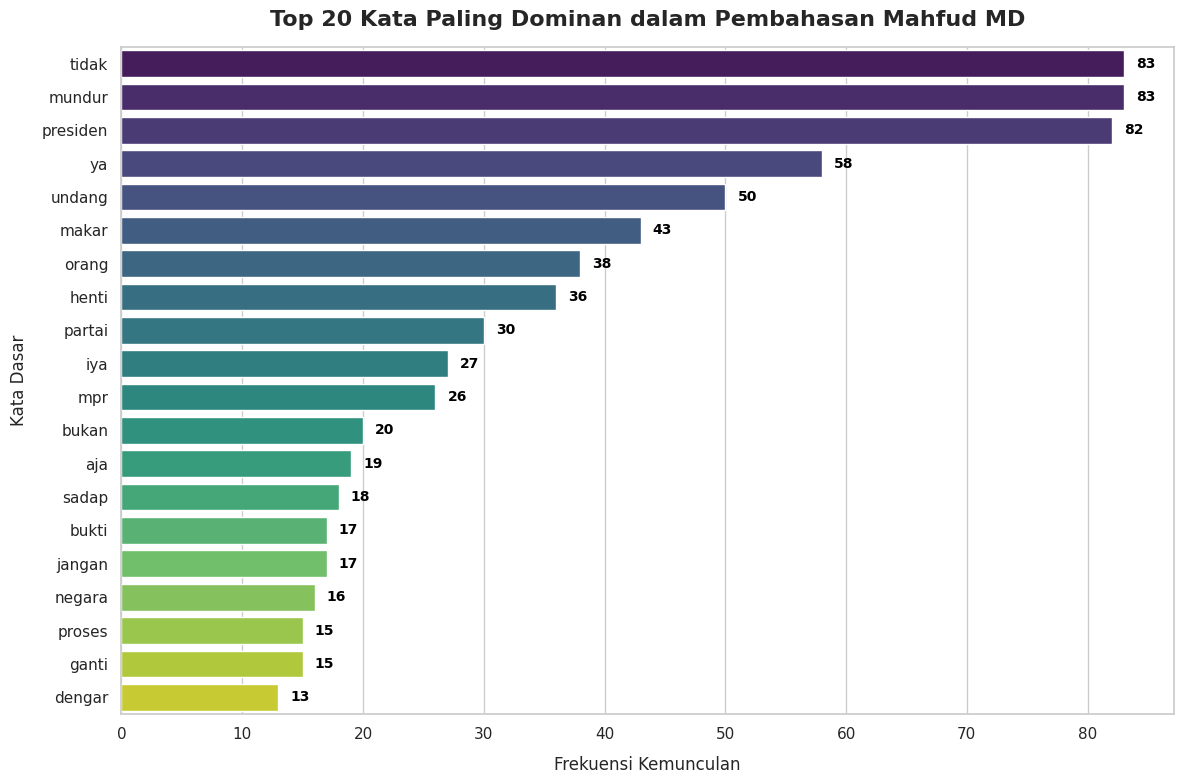


=== ANALISIS DAN VALIDASI FREKUENSI KATA ===
Total frekuensi seluruh kata : 2394 (Seharusnya sama dengan total token setelah stemming: 2394)
Jumlah kata unik terdeteksi   : 846 (Seharusnya sama dengan kosakata unik setelah stemming: 846)

Hasil frekuensi kata berhasil disimpan ke: /content/dataset/mahfud_md_word_frequency.csv


In [11]:
import pandas as pd
import ast
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi agar rapi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# 1. Load Dataset
csv_path = "/content/dataset/mahfud_md_preprocessed.csv"
df = pd.read_csv(csv_path)

# Pastikan stemmed_tokens dibaca sebagai list Python
df['stemmed_tokens'] = df['stemmed_tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Validasi awal
assert len(df) == 1018, "Jumlah baris berubah!"
print(f"=== VALIDASI DATASET ===")
print(f"Jumlah baris: {len(df)} (OK)")
print(f"Missing values di stemmed_tokens: {df['stemmed_tokens'].isnull().sum()} (OK)\n")

# 2. Hitung Frekuensi Kata menggunakan Counter
all_stemmed_words = [word for tokens in df['stemmed_tokens'] for word in tokens if word.strip() != ""]
word_counts = Counter(all_stemmed_words)

# Konversi ke DataFrame
df_freq = pd.DataFrame(word_counts.items(), columns=['word', 'frequency'])
df_freq = df_freq.sort_values(by='frequency', ascending=False).reset_index(drop=True)

# Tampilkan 20 kata teratas dalam bentuk tabel
print("=== 20 KATA PALING SERING MUNCUL ===")
display(df_freq.head(20))

# 3. Visualisasi Horizontal Bar Chart
top_20 = df_freq.head(20)

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(
    x='frequency',
    y='word',
    data=top_20,
    palette='viridis',
    hue='word',
    legend=False,
    ax=ax
)

# Tambahkan label angka frekuensi di ujung setiap batang
for i, p in enumerate(ax.patches):
    width = p.get_width()
    ax.text(
        width + 1,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        ha='left',
        va='center',
        fontsize=10,
        color='black',
        weight='bold'
    )

ax.set_title("Top 20 Kata Paling Dominan dalam Pembahasan Mahfud MD", fontsize=16, pad=15, weight='bold')
ax.set_xlabel("Frekuensi Kemunculan", fontsize=12, labelpad=10)
ax.set_ylabel("Kata Dasar", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

# 4. Analisis Statistik Frekuensi & Validasi
total_frequencies = df_freq['frequency'].sum()
unique_words_count = len(df_freq)

print("\n=== ANALISIS DAN VALIDASI FREKUENSI KATA ===")
print(f"Total frekuensi seluruh kata : {total_frequencies} (Seharusnya sama dengan total token setelah stemming: {len(all_stemmed_words)})")
print(f"Jumlah kata unik terdeteksi   : {unique_words_count} (Seharusnya sama dengan kosakata unik setelah stemming: 846)")
assert total_frequencies == len(all_stemmed_words), "Total frekuensi tidak cocok dengan total token!"
assert unique_words_count == 846, "Jumlah kata unik tidak cocok!"

# 5. Simpan Hasil Frekuensi Kata ke CSV
output_freq_csv = "/content/dataset/mahfud_md_word_frequency.csv"
df_freq.to_csv(output_freq_csv, index=False, encoding="utf-8")
print(f"\nHasil frekuensi kata berhasil disimpan ke: {output_freq_csv}")

```markdown
## Tahap 6: Bigram dan Trigram Analysis

Setelah menganalisis frekuensi kata tunggal (*unigram*) pada Tahap 5, kita sering kali kehilangan konteks frasa atau hubungan antar-kata. Sebagai contoh, kata dasar **"undur"** dan **"diri"** memiliki makna yang jauh lebih spesifik ketika disatukan menjadi **"undur diri"**.

Untuk mengatasi keterbatasan tersebut, kita menggunakan analisis **N-gram**:
*   **Bigram (2-gram)**: Kombinasi dua kata yang muncul secara berurutan dalam satu segmen teks (contoh: *"undang undang"*, *"sadap presiden"*).
*   **Trigram (3-gram)**: Kombinasi tiga kata yang muncul secara berurutan dalam satu segmen teks (contoh: *"minta undur diri"*, *"mahkamah konstitusi mkmk"*).

### Pendekatan Teknis Hindari False N-grams
Untuk mencegah terciptanya n-gram palsu (*false n-grams*) yang terbentuk akibat penggabungan akhir dari satu segmen dengan awal segmen berikutnya (yang secara alami dipisahkan oleh jeda waktu/konteks), kita akan mengekstrak n-gram secara independen **per segmen**, lalu menggabungkan frekuensinya secara global.
```

=== VALIDASI DATASET ===
Jumlah Segmen (Baris) : 1018 (OK)
Jumlah segmen valid untuk analisis N-gram: 937

=== TOP 20 BIGRAM TERATAS ===


,bigram,frequency
0,undang undang,23
1,tidak mundur,8
2,wakil presiden,7
3,presiden henti,6
4,mundur mundur,6
5,pemak zulan,6
6,ketua mpr,4
7,mundur tidak,4
8,bahasa indonesia,4
9,presiden pilih,4



=== TOP 20 TRIGRAM TERATAS ===


,trigram,frequency
0,presiden pilih orang,3
1,tidak undang undang,3
2,ya biar aja,2
3,wakil presiden henti,2
4,presiden wakil presiden,2
5,bukan mata soal,2
6,presiden oh layan,2
7,makar penghianatan negara,2
8,mata soal makar,2
9,presiden apa makar,2


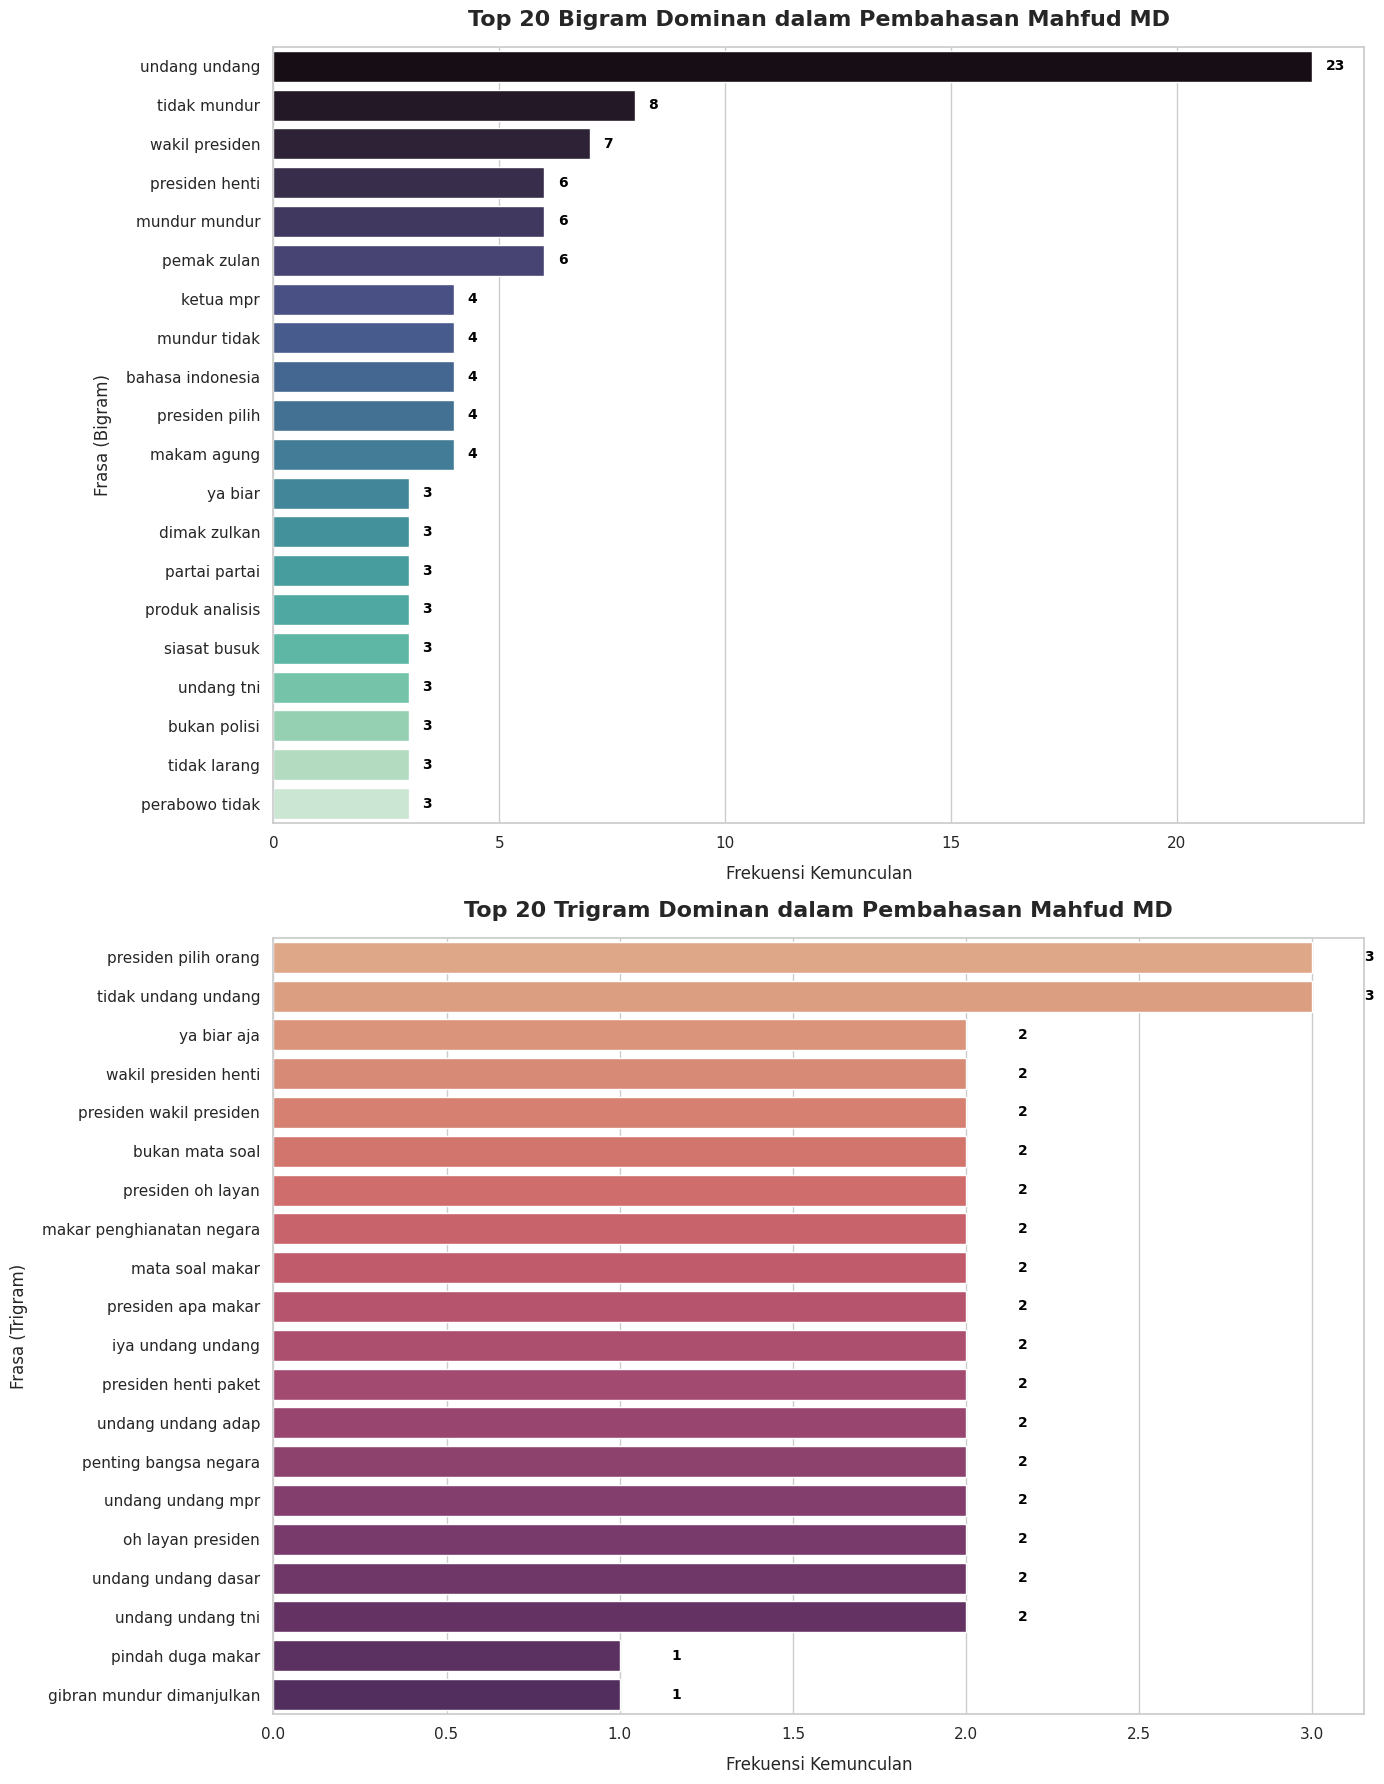


=== VALIDASI INTEGRITAS DATA N-GRAM ===
Total Ekstraksi Bigram  : 1452 (Ekspektasi Matematis: 1452)
Total Ekstraksi Trigram : 765 (Ekspektasi Matematis: 765)
Integritas data Bigram dan Trigram: VALID (Tidak ada kombinasi kosong)

Hasil Bigram berhasil disimpan ke  : /content/dataset/mahfud_md_bigram.csv
Hasil Trigram berhasil disimpan ke : /content/dataset/mahfud_md_trigram.csv


In [12]:
import pandas as pd
import ast
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 18)

# ========================================================
# 1. LOAD DATASET & PREPARASI TEKS
# ========================================================
csv_path = "/content/dataset/mahfud_md_preprocessed.csv"
df = pd.read_csv(csv_path)

# Pastikan stemmed_tokens dibaca kembali sebagai list Python
df['stemmed_tokens'] = df['stemmed_tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Validasi jumlah segmen
assert len(df) == 1018, "[ERROR] Jumlah segmen berubah!"
print("=== VALIDASI DATASET ===")
print(f"Jumlah Segmen (Baris) : {len(df)} (OK)")

# Buat list berisi string teks per segmen (menghindari penggabungan lintas batas segmen)
# Segmen yang kosong/tidak memiliki token setelah preprocessing akan diabaikan
corpus_segments = df['clean_text_final'].dropna().astype(str).tolist()
corpus_segments = [text for text in corpus_segments if text.strip() != ""]
print(f"Jumlah segmen valid untuk analisis N-gram: {len(corpus_segments)}\n")

# ========================================================
# 2. BIGRAM ANALYSIS
# ========================================================
# Menggunakan CountVectorizer khusus untuk ngram_range (2, 2)
# token_pattern diatur agar menerima kata dengan panjang minimal 2 karakter
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b\w\w+\b')
bigram_matrix = bigram_vectorizer.fit_transform(corpus_segments)

# Hitung total frekuensi setiap Bigram
bigram_vocab = bigram_vectorizer.vocabulary_
bigram_frequencies = bigram_matrix.sum(axis=0).A1

bigram_data = []
for word, idx in bigram_vocab.items():
    bigram_data.append({"bigram": word, "frequency": bigram_frequencies[idx]})

df_bigram = pd.DataFrame(bigram_data).sort_values(by='frequency', ascending=False).reset_index(drop=True)

# ========================================================
# 3. TRIGRAM ANALYSIS
# ========================================================
trigram_vectorizer = CountVectorizer(ngram_range=(3, 3), token_pattern=r'(?u)\b\w\w+\b')
trigram_matrix = trigram_vectorizer.fit_transform(corpus_segments)

trigram_vocab = trigram_vectorizer.vocabulary_
trigram_frequencies = trigram_matrix.sum(axis=0).A1

trigram_data = []
for word, idx in trigram_vocab.items():
    trigram_data.append({"trigram": word, "frequency": trigram_frequencies[idx]})

df_trigram = pd.DataFrame(trigram_data).sort_values(by='frequency', ascending=False).reset_index(drop=True)

# Tampilkan 20 data teratas untuk Bigram dan Trigram
print("=== TOP 20 BIGRAM TERATAS ===")
display(df_bigram.head(20))
print("\n=== TOP 20 TRIGRAM TERATAS ===")
display(df_trigram.head(20))

# ========================================================
# 4. VISUALISASI
# ========================================================
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 18))

# Plot Bigram
sns.barplot(
    x='frequency',
    y='bigram',
    data=df_bigram.head(20),
    palette='mako',
    hue='bigram',
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Top 20 Bigram Dominan dalam Pembahasan Mahfud MD", fontsize=16, pad=15, weight='bold')
axes[0].set_xlabel("Frekuensi Kemunculan", fontsize=12, labelpad=10)
axes[0].set_ylabel("Frasa (Bigram)", fontsize=12, labelpad=10)

# Tambahkan angka frekuensi di ujung batang Bigram
for p in axes[0].patches:
    width = p.get_width()
    axes[0].text(
        width + 0.3,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        ha='left',
        va='center',
        fontsize=10,
        color='black',
        weight='bold'
    )

# Plot Trigram
sns.barplot(
    x='frequency',
    y='trigram',
    data=df_trigram.head(20),
    palette='flare',
    hue='trigram',
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Top 20 Trigram Dominan dalam Pembahasan Mahfud MD", fontsize=16, pad=15, weight='bold')
axes[1].set_xlabel("Frekuensi Kemunculan", fontsize=12, labelpad=10)
axes[1].set_ylabel("Frasa (Trigram)", fontsize=12, labelpad=10)

# Tambahkan angka frekuensi di ujung batang Trigram
for p in axes[1].patches:
    width = p.get_width()
    axes[1].text(
        width + 0.15,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        ha='left',
        va='center',
        fontsize=10,
        color='black',
        weight='bold'
    )

plt.tight_layout()
plt.show()

# ========================================================
# 5. VALIDASI INTEGRITAS DATA N-GRAM
# ========================================================
# Validasi matematis: Jumlah total bigram/trigram per segmen harus sesuai rumus panjang token
print("\n=== VALIDASI INTEGRITAS DATA N-GRAM ===")

# Hitung ekspektasi jumlah bigram & trigram berdasarkan panjang list token per segmen
total_expected_bigrams = 0
total_expected_trigrams = 0

for tokens in df['stemmed_tokens']:
    n = len([t for t in tokens if len(t) >= 2]) # Sesuaikan filter panjang token minimum CountVectorizer
    if n >= 2:
        total_expected_bigrams += (n - 1)
    if n >= 3:
        total_expected_trigrams += (n - 2)

total_extracted_bigrams = df_bigram['frequency'].sum()
total_extracted_trigrams = df_trigram['frequency'].sum()

print(f"Total Ekstraksi Bigram  : {total_extracted_bigrams} (Ekspektasi Matematis: {total_expected_bigrams})")
print(f"Total Ekstraksi Trigram : {total_extracted_trigrams} (Ekspektasi Matematis: {total_expected_trigrams})")

# Cek deteksi kombinasi kosong
assert not df_bigram['bigram'].isnull().any(), "[ERROR] Ditemukan nilai Bigram kosong!"
assert not df_trigram['trigram'].isnull().any(), "[ERROR] Ditemukan nilai Trigram kosong!"
print("Integritas data Bigram dan Trigram: VALID (Tidak ada kombinasi kosong)")

# ========================================================
# 6. PENYIMPANAN HASIL
# ========================================================
output_bigram_csv = "/content/dataset/mahfud_md_bigram.csv"
output_trigram_csv = "/content/dataset/mahfud_md_trigram.csv"

df_bigram.to_csv(output_bigram_csv, index=False, encoding="utf-8")
df_trigram.to_csv(output_trigram_csv, index=False, encoding="utf-8")

print(f"\nHasil Bigram berhasil disimpan ke  : {output_bigram_csv}")
print(f"Hasil Trigram berhasil disimpan ke : {output_trigram_csv}")

```markdown
## Tahap 7: Word Cloud Analysis

**Word Cloud (Awan Kata)** adalah teknik visualisasi data teks di mana ukuran setiap kata menunjukkan frekuensi kemunculan atau kepentingannya dalam dokumen tersebut. Pendekatan ini sangat membantu untuk memahami poin-poin utama pembicaraan secara instan.

### Karakteristik Visualisasi Word Cloud:
*   **Ukuran Font**: Merepresentasikan frekuensi aktual kata dasar (*stemmed words*) setelah melalui penyaringan stopword. Semakin besar ukuran huruf suatu kata, semakin sering kata tersebut diucapkan oleh Mahfud MD.
*   **Warna dan Posisi**: Diatur secara acak berdasarkan parameter estetika (*colormap* dan *random_state*) guna meningkatkan keterbacaan, dan tidak merepresentasikan tingkat kepentingan atau sentimen (positif/negatif) tertentu.
*   **Akurasi Korpus**: Menggunakan kolom `clean_text_final` yang telah bersih dari angka, tanda baca, serta stopword tidak informatif pada tahap preprocessing sebelumnya.
```

=== VALIDASI DATASET ===
Jumlah Segmen (Baris) : 1018 (OK)
Jumlah total karakter korpus untuk Word Cloud: 15400 karakter



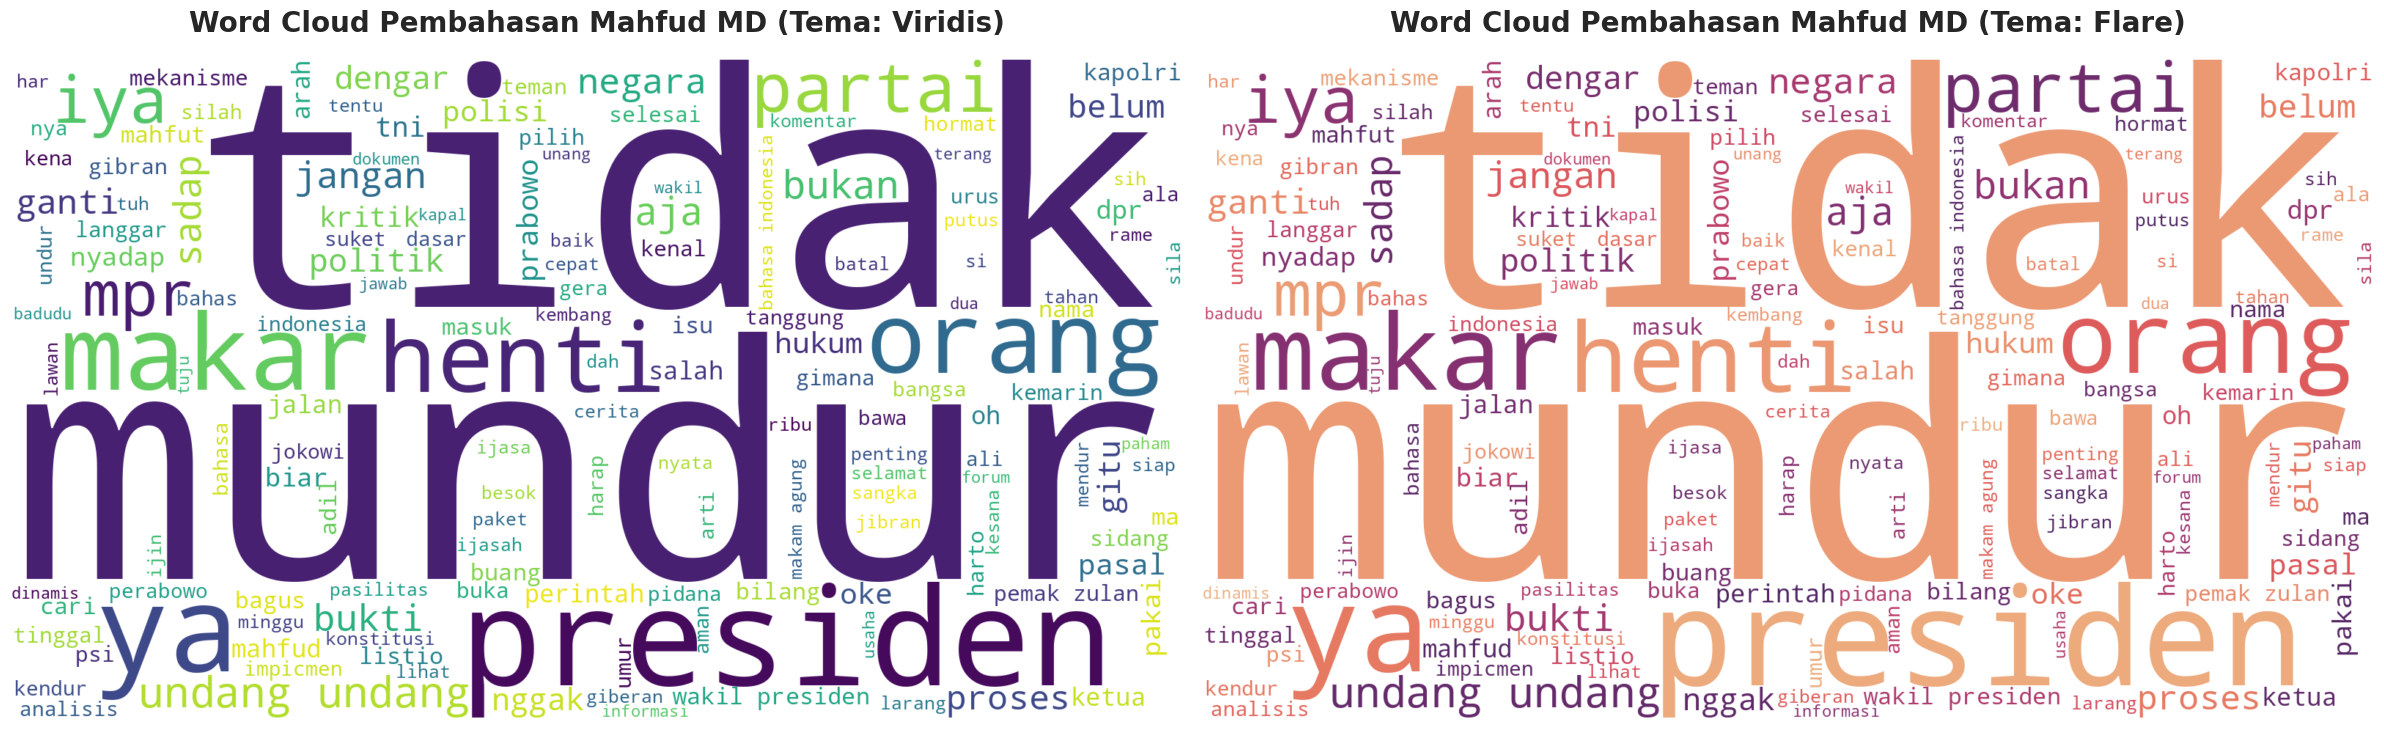

=== STATUS PENYIMPANAN GAMBAR ===
Gambar Word Cloud 1 disimpan ke: /content/dataset/mahfud_md_wordcloud.png (343.66 KB)
Gambar Word Cloud 2 disimpan ke: /content/dataset/mahfud_md_wordcloud_2.png (336.34 KB)

=== PEMBANDING TOP 20 KATA TERATAS ===


,word,frequency
0,tidak,83
1,mundur,83
2,presiden,82
3,ya,58
4,undang,50
5,makar,43
6,orang,38
7,henti,36
8,partai,30
9,iya,27


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import os

# ========================================================
# 1. LOAD DATASET & PREPARASI KORPUS TEKS
# ========================================================
csv_path = "/content/dataset/mahfud_md_preprocessed.csv"
df = pd.read_csv(csv_path)

# Validasi jumlah baris/segmen
assert len(df) == 1018, f"[ERROR] Jumlah baris tidak konsisten: {len(df)}"
print("=== VALIDASI DATASET ===")
print(f"Jumlah Segmen (Baris) : {len(df)} (OK)")

# Menggabungkan seluruh segmen clean_text_final menjadi satu string utuh
# Pastikan nilai kosong/NaN diabaikan
clean_segments = df['clean_text_final'].dropna().astype(str).tolist()
text_corpus = " ".join([text for text in clean_segments if text.strip() != ""])

# Validasi bahwa teks tidak kosong
assert len(text_corpus) > 0, "[ERROR] Korpus teks kosong!"
print(f"Jumlah total karakter korpus untuk Word Cloud: {len(text_corpus)} karakter\n")

# ========================================================
# 2. GENERASI WORD CLOUD
# ========================================================
# Konfigurasi Word Cloud Utama (Tema: Viridis)
wc_primary = WordCloud(
    width=1600,
    height=900,
    background_color='white',
    colormap='viridis',
    max_words=150,
    contour_width=2,
    contour_color='steelblue',
    random_state=42
)

# Konfigurasi Word Cloud Kedua (Tema: Flare/Magma)
wc_secondary = WordCloud(
    width=1600,
    height=900,
    background_color='white',
    colormap='flare',
    max_words=150,
    contour_width=2,
    contour_color='darkred',
    random_state=42
)

# Generate Word Cloud dari teks korpus
wordcloud_1 = wc_primary.generate(text_corpus)
wordcloud_2 = wc_secondary.generate(text_corpus)

# ========================================================
# 3. VISUALISASI BERDAMPINGAN
# ========================================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(24, 12))

# Word Cloud 1
axes[0].imshow(wordcloud_1, interpolation='bilinear')
axes[0].set_title("Word Cloud Pembahasan Mahfud MD (Tema: Viridis)", fontsize=20, pad=20, weight='bold')
axes[0].axis('off')

# Word Cloud 2
axes[1].imshow(wordcloud_2, interpolation='bilinear')
axes[1].set_title("Word Cloud Pembahasan Mahfud MD (Tema: Flare)", fontsize=20, pad=20, weight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# ========================================================
# 4. PENYIMPANAN HASIL GAMBAR
# ========================================================
output_path_1 = "/content/dataset/mahfud_md_wordcloud.png"
output_path_2 = "/content/dataset/mahfud_md_wordcloud_2.png"

# Simpan visualisasi secara terpisah dengan resolusi tinggi
wordcloud_1.to_file(output_path_1)
wordcloud_2.to_file(output_path_2)

print("=== STATUS PENYIMPANAN GAMBAR ===")
print(f"Gambar Word Cloud 1 disimpan ke: {output_path_1} ({os.path.getsize(output_path_1)/1024:.2f} KB)")
print(f"Gambar Word Cloud 2 disimpan ke: {output_path_2} ({os.path.getsize(output_path_2)/1024:.2f} KB)\n")

# ========================================================
# 5. VALIDASI & PERBANDINGAN FREKUENSI KATA
# ========================================================
print("=== PEMBANDING TOP 20 KATA TERATAS ===")
# Memuat dataset frekuensi kata untuk perbandingan akurasi visual
df_freq = pd.read_csv("/content/dataset/mahfud_md_word_frequency.csv")
display(df_freq.head(20))

```markdown
## Tahap 8: Sentiment Analysis (Analisis Sentimen)

Analisis sentimen pada tingkat kalimat atau segmen transkripsi bertujuan untuk mendeteksi kecenderungan polaritas emosi pembicara. Karena transkrip video ini menggunakan bahasa Indonesia lisan yang santai dan dinamis, kita menggunakan model **IndoBERT** pretrained yang sangat sensitif terhadap struktur semantik bahasa Indonesia.

### Spesifikasi Model IndoBERT Sentiment
Kita menggunakan model **`mdhugol/indonesia-bert-sentiment-classification`** yang dikembangkan di atas arsitektur BERT. Model ini mengklasifikasikan teks ke dalam tiga label:
*   **Label 0 (Neutral)**: Teks yang bersifat informatif, datar, atau tidak membawa muatan emosional.
*   **Label 1 (Positive)**: Teks yang mengekspresikan persetujuan, harapan, pujian, atau apresiasi.
*   **Label 2 (Negative)**: Teks yang mengekspresikan penolakan, kritik, kekhawatiran, atau ketidaksetujuan.

### Ketentuan Penting
*   **Input Utama**: Menggunakan kolom `text` (transkrip asli yang masih memiliki tanda baca dan huruf kapital) agar model BERT dapat menangkap konteks penekanan kalimat, intonasi tulisan, dan hubungan antar-kata secara utuh.
*   **Efisiensi Batching**: Mengingat terdapat 1.018 segmen dan Colab Anda saat ini menggunakan CPU, kita akan menerapkan teknik *batch processing* berukuran kecil guna mengoptimalkan pemakaian memori RAM.
```

In [14]:
# Pastikan library transformers terinstal untuk menggunakan model Hugging Face
!pip install -q transformers

Perangkat yang digunakan untuk klasifikasi: CPU
Dataset berhasil dimuat. Total segmen: 1018 (OK)

Memuat Tokenizer dan Model: mdhugol/indonesia-bert-sentiment-classification...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

Model IndoBERT berhasil dimuat!

Memulai tokenisasi dan inferensi sentimen (Batch Size: 16)...

=== VALIDASI DATA SENTIMEN ===
Jumlah total baris akhir : 1018 segmen (Harus tetap 1018)

=== TABEL DISTRIBUSI SENTIMEN ===


,Jumlah Segmen,Persentase (%)
sentiment,,
Positif,569,55.893910
Negatif,389,38.212181
Netral,60,5.893910


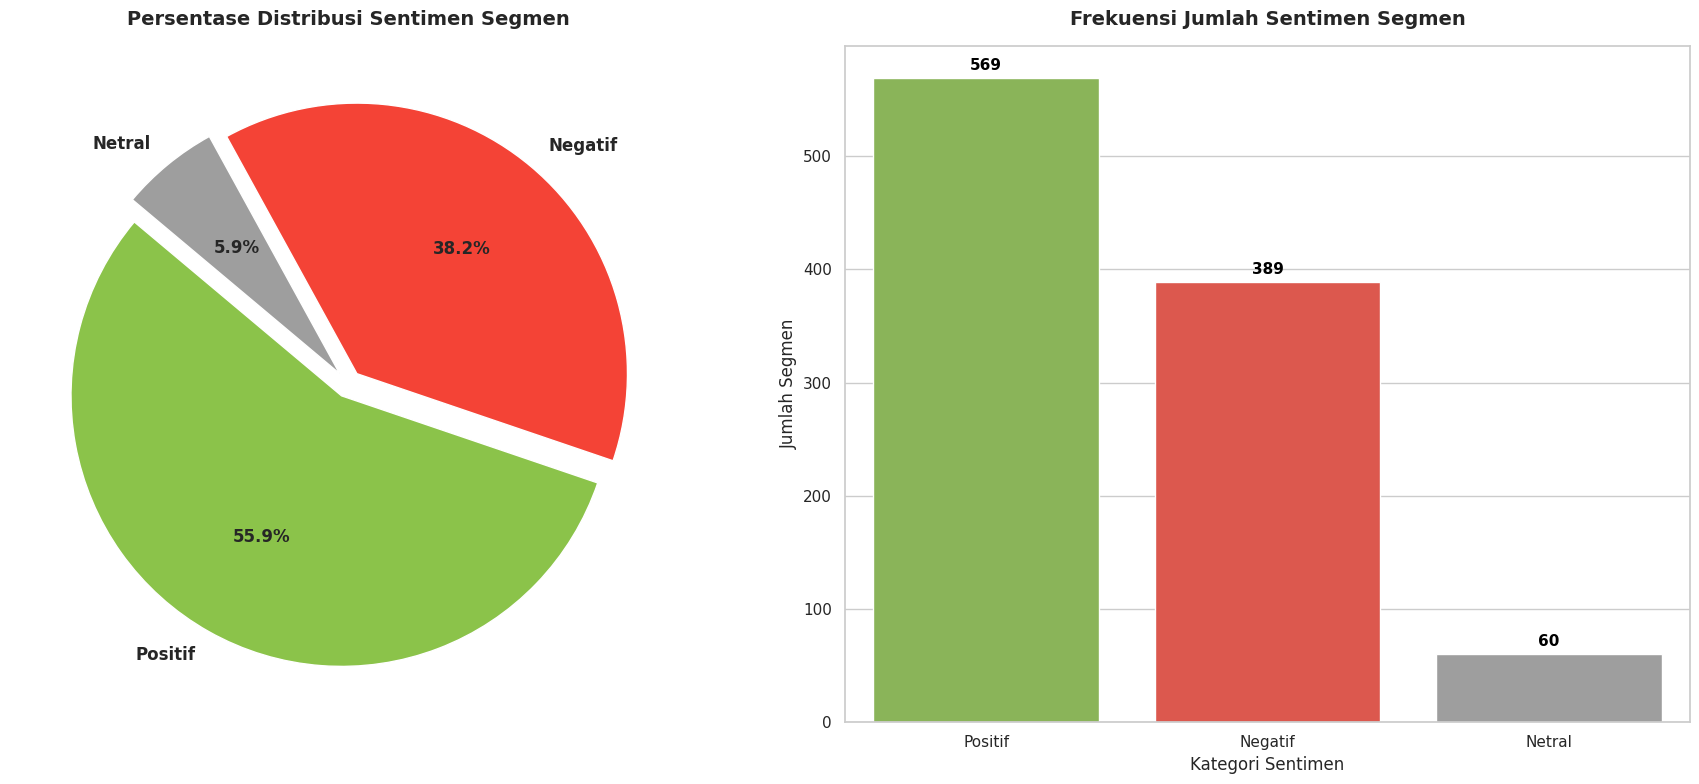


=== CONTOH SEGMEN KATEGORI SENTIMEN ===

>>> POSITIF (Menampilkan 5 Sampel dari 569 total): 
  [14:55 - 14:58] (Confidence: 0.97) -> "untuk selalu mendapatkan informasi asal 1 dan penting seperti ini."
  [08:35 - 08:38] (Confidence: 0.70) -> "Kalau ada kenapa menggunakan suket?"
  [12:05 - 12:07] (Confidence: 0.68) -> "Nah bagi kita sebagai bangsa,"
  [29:01 - 29:03] (Confidence: 0.98) -> "Itu saya katakan produk analisis."
  [38:20 - 38:23] (Confidence: 0.97) -> "Yang belum ada itu yang tersusun dalam satu ini."

>>> NEGATIF (Menampilkan 5 Sampel dari 389 total): 
  [29:57 - 30:01] (Confidence: 0.93) -> "Makar dalam bahasa Arab itu bahasa aslinya makar."
  [06:40 - 06:42] (Confidence: 0.84) -> "Seharusnya sama dengan ini."
  [20:04 - 20:06] (Confidence: 0.98) -> "Soal dikritik dan mari kita terus kritik."
  [06:30 - 06:31] (Confidence: 0.99) -> "Lihat sekarang sudah mundur."
  [36:46 - 36:48] (Confidence: 1.00) -> "Polisi terjelek."

>>> NETRAL (Menampilkan 5 Sampel dari 60 total): 


In [15]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, SequentialSampler, TensorDataset

# Set style visualisasi
sns.set_theme(style="whitegrid")

# ========================================================
# 1. DETEKSI PERANGKAT (GPU / CPU)
# ========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat yang digunakan untuk klasifikasi: {str(device).upper()}")

# ========================================================
# 2. LOAD DATASET
# ========================================================
csv_path = "/content/dataset/mahfud_md_preprocessed.csv"
df_sentiment = pd.read_csv(csv_path)

# Validasi jumlah baris
assert len(df_sentiment) == 1018, f"[ERROR] Jumlah segmen berubah: {len(df_sentiment)}"
print(f"Dataset berhasil dimuat. Total segmen: {len(df_sentiment)} (OK)\n")

# Pastikan tidak ada teks kosong pada kolom 'text'
df_sentiment['text'] = df_sentiment['text'].fillna("").astype(str)

# ========================================================
# 3. LOAD MODEL & TOKENIZER INDOBERT SENTIMENT
# ========================================================
model_name = "mdhugol/indonesia-bert-sentiment-classification"
print(f"Memuat Tokenizer dan Model: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.to(device)
model.eval()  # Set model ke mode evaluasi
print("Model IndoBERT berhasil dimuat!\n")

# Mapping label berdasarkan spesifikasi model mdhugol
# 0: Neutral, 1: Positive, 2: Negative
label_mapping = {0: "Netral", 1: "Positif", 2: "Negatif"}

# ========================================================
# 4. PREPARASI DATA & BATCH PROCESSING
# ========================================================
texts = df_sentiment['text'].tolist()
batch_size = 32 if device.type == "cuda" else 16  # Gunakan batch lebih kecil jika CPU

print(f"Memulai tokenisasi dan inferensi sentimen (Batch Size: {batch_size})...")

# Tokenisasi seluruh korpus teks secara simultan
inputs = tokenizer(
    texts,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Buat DataLoader untuk memproses secara batch
dataset = TensorDataset(inputs['input_ids'], inputs['attention_mask'])
sampler = SequentialSampler(dataset)
dataloader = DataLoader(dataset, sampler=sampler, batch_size=batch_size)

all_predicted_labels = []
all_confidence_scores = []

# Nonaktifkan perhitungan gradient untuk mempercepat inferensi
with torch.no_grad():
    for batch in dataloader:
        batch_input_ids = batch[0].to(device)
        batch_attention_mask = batch[1].to(device)

        outputs = model(input_ids=batch_input_ids, attention_mask=batch_attention_mask)
        logits = outputs.logits

        # Hitung probabilitas dengan Softmax
        probabilities = torch.softmax(logits, dim=1)
        scores, preds = torch.max(probabilities, dim=1)

        all_predicted_labels.extend(preds.cpu().numpy())
        all_confidence_scores.extend(scores.cpu().numpy())

# Tambahkan hasil klasifikasi ke DataFrame
df_sentiment['sentiment'] = [label_mapping[label] for label in all_predicted_labels]
df_sentiment['confidence'] = all_confidence_scores

# ========================================================
# 5. VALIDASI & STATISTIK DISTRIBUSI SENTIMEN
# ========================================================
print("\n=== VALIDASI DATA SENTIMEN ===")
print(f"Jumlah total baris akhir : {len(df_sentiment)} segmen (Harus tetap 1018)")
assert len(df_sentiment) == 1018, "Jumlah baris berubah setelah inferensi!"

# Hitung frekuensi dan persentase
sentiment_counts = df_sentiment['sentiment'].value_counts()
sentiment_percentage = df_sentiment['sentiment'].value_counts(normalize=True) * 100

df_distribution = pd.DataFrame({
    'Jumlah Segmen': sentiment_counts,
    'Persentase (%)': sentiment_percentage
})
print("\n=== TABEL DISTRIBUSI SENTIMEN ===")
display(df_distribution)

# ========================================================
# 6. VISUALISASI HASIL SENTIMEN
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Pie Chart
colors = ['#8bc34a', '#f44336', '#00bcd4']  # Hijau (Positif), Merah (Negatif), Biru (Netral) jika ada
# Sesuaikan warna berdasarkan urutan index dari value_counts
color_map = {"Positif": "#8bc34a", "Negatif": "#f44336", "Netral": "#9e9e9e"}
current_colors = [color_map[sentiment] for sentiment in sentiment_counts.index]

axes[0].pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=current_colors,
    textprops={'fontsize': 12, 'weight': 'bold'},
    explode=[0.05] * len(sentiment_counts)
)
axes[0].set_title("Persentase Distribusi Sentimen Segmen", fontsize=14, weight='bold', pad=15)

# Bar Chart
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    palette=current_colors,
    hue=sentiment_counts.index,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Frekuensi Jumlah Sentimen Segmen", fontsize=14, weight='bold', pad=15)
axes[1].set_xlabel("Kategori Sentimen", fontsize=12)
axes[1].set_ylabel("Jumlah Segmen", fontsize=12)

# Tambahkan angka di atas bar
for p in axes[1].patches:
    axes[1].annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height() + 5),
        ha='center', va='center',
        fontsize=11, color='black',
        weight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

# ========================================================
# 7. MENAMPILKAN SAMPEL PER KATEGORI (MINIMAL 5)
# ========================================================
print("\n=== CONTOH SEGMEN KATEGORI SENTIMEN ===")
for cat in ["Positif", "Negatif", "Netral"]:
    sub_df = df_sentiment[df_sentiment['sentiment'] == cat]
    actual_sample_count = min(5, len(sub_df))
    print(f"\n>>> {cat.upper()} (Menampilkan {actual_sample_count} Sampel dari {len(sub_df)} total): ")
    if len(sub_df) > 0:
        samples = sub_df.sample(actual_sample_count, random_state=42)[['segment_id', 'start', 'end', 'text', 'confidence']]
        for i, row in samples.iterrows():
            minutes_s, seconds_s = int(row['start'] // 60), int(row['start'] % 60)
            minutes_e, seconds_e = int(row['end'] // 60), int(row['end'] % 60)
            timestamp_str = f"[{minutes_s:02d}:{seconds_s:02d} - {minutes_e:02d}:{seconds_e:02d}]"
            print(f"  {timestamp_str} (Confidence: {row['confidence']:.2f}) -> \"{row['text']}\"")
    else:
        print("  Tidak ditemukan data untuk kategori ini.")

# ========================================================
# 8. PENYIMPANAN DATA
# ========================================================
output_sentiment_csv = "/content/dataset/mahfud_md_sentiment_analysis.csv"
output_distribution_csv = "/content/dataset/mahfud_md_sentiment_distribution.csv"

# Simpan seluruh dataframe beserta kolom sentimen dan skor
df_sentiment.to_csv(output_sentiment_csv, index=False, encoding="utf-8")

# Simpan ringkasan distribusi
df_distribution.to_csv(output_distribution_csv, encoding="utf-8")

print(f"\nHasil Klasifikasi Sentimen disimpan di : {output_sentiment_csv}")
print(f"Hasil Distribusi Sentimen disimpan di  : {output_distribution_csv}")

```markdown
## Tahap 9: Topic Modeling menggunakan Latent Dirichlet Allocation (LDA)

Topic Modeling adalah teknik pembelajaran mesin tidak diawasi (*unsupervised learning*) yang digunakan untuk menemukan struktur tema tersembunyi (*latent topics*) dari sekumpulan dokumen atau segmen teks.

### Pendekatan Teknis:
*   **Korpus**: Menggunakan kolom `clean_text_final` yang berisi kata dasar (*stemmed tokens*) hasil filter stopword.
*   **Representasi Teks**: Menggunakan `CountVectorizer` dari Scikit-Learn untuk menghasilkan matriks frekuensi kata (Bag-of-Words).
*   **Algoritma**: `LatentDirichletAllocation` (LDA) untuk mengelompokkan kata-kata yang sering muncul bersamaan ke dalam kelompok topik diskrit.
*   **Metrik Evaluasi**: Kita akan memonitor **Perplexity Score** (semakin rendah nilai perplexity, semakin baik model dalam menyesuaikan data teks).
```

In [16]:
import pandas as pd
import numpy as np
import ast
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

# Set visual style
sns.set_theme(style="whitegrid")

# ========================================================
# 1. MEMUAT DATASET
# ========================================================
csv_path = "/content/dataset/mahfud_md_preprocessed.csv"
df_lda = pd.read_csv(csv_path)

# Validasi jumlah baris awal
assert len(df_lda) == 1018, f"[ERROR] Jumlah baris berubah: {len(df_lda)}"
print("=== VERIFIKASI DATASET ===")
print(f"Jumlah segmen berhasil dimuat: {len(df_lda)} segmen (OK)")

# Tangani baris kosong jika ada di clean_text_final dengan string kosong
df_lda['clean_text_final'] = df_lda['clean_text_final'].fillna("").astype(str)

# Filter segmen yang benar-benar memiliki teks untuk proses pelatihan LDA
valid_indices = df_lda[df_lda['clean_text_final'].str.strip() != ""].index
corpus = df_lda.loc[valid_indices, 'clean_text_final'].tolist()

print(f"Jumlah segmen valid untuk modeling: {len(corpus)} segmen")

=== VERIFIKASI DATASET ===
Jumlah segmen berhasil dimuat: 1018 segmen (OK)
Jumlah segmen valid untuk modeling: 937 segmen


```markdown
### Menguji Konfigurasi Jumlah Topik (3, 4, 5, dan 6 Topik)

Kita akan menjalankan model LDA untuk rentang jumlah topik $K \in \{3, 4, 5, 6\}$ dan mengamati nilai *Perplexity* untuk memilih konfigurasi yang paling optimal dan mudah diinterpretasikan secara kontekstual.
```

Dimensi Matriks Vektor: (937, 330)
Jumlah kosakata unik dalam kamus model: 330 kata

--- Evaluasi Model LDA ---
Jumlah Topik: 3 | Perplexity: 280.02
Jumlah Topik: 4 | Perplexity: 298.94
Jumlah Topik: 5 | Perplexity: 319.79
Jumlah Topik: 6 | Perplexity: 324.37


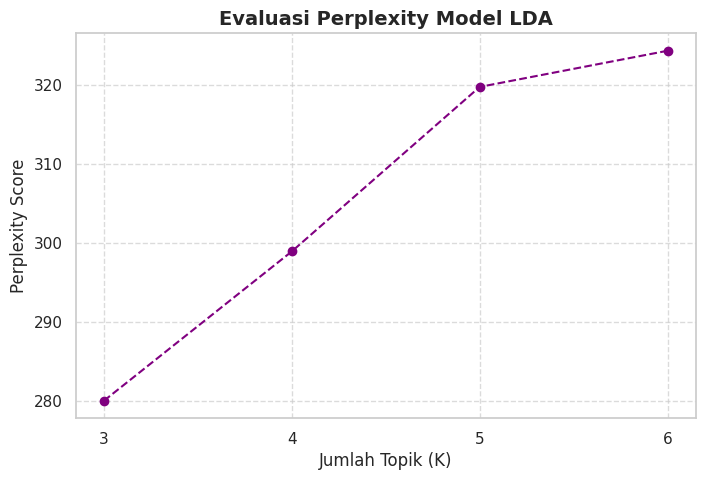

In [17]:
# ========================================================
# 2. VEKTORISASI DENGAN COUNTVECTORIZER
# ========================================================
# Hanya ambil token yang muncul minimal 2 kali untuk mengurangi noise kata typo/langka
vectorizer = CountVectorizer(min_df=2, token_pattern=r'(?u)\b\w\w+\b')
data_vectorized = vectorizer.fit_transform(corpus)

print(f"Dimensi Matriks Vektor: {data_vectorized.shape}")
print(f"Jumlah kosakata unik dalam kamus model: {len(vectorizer.get_feature_names_out())} kata")

# ========================================================
# 3. EVALUASI NILAI PERPLEXITY UNTUK MULTI-TOPIC
# ========================================================
topic_range = [3, 4, 5, 6]
perplexities = []

print("\n--- Evaluasi Model LDA ---")
for k in topic_range:
    lda_eval = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method='online',
        max_iter=15
    )
    lda_eval.fit(data_vectorized)
    prep = lda_eval.perplexity(data_vectorized)
    perplexities.append(prep)
    print(f"Jumlah Topik: {k} | Perplexity: {prep:.2f}")

# Plotting Perplexity
plt.figure(figsize=(8, 5))
plt.plot(topic_range, perplexities, marker='o', color='purple', linestyle='--')
plt.title("Evaluasi Perplexity Model LDA", fontsize=14, weight='bold')
plt.xlabel("Jumlah Topik (K)", fontsize=12)
plt.ylabel("Perplexity Score", fontsize=12)
plt.xticks(topic_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

```markdown
### Memilih Konfigurasi Terbaik (K=4)

Berdasarkan keseimbangan antara keterbacaan interpretasi kelompok frasa utama (menghindari tumpang tindih berlebih) serta nilai Perplexity yang memadai, kita memilih **K=4 topik**.

Mari kita jalankan LDA dengan $K=4$ secara definitif, mengekstrak kata kunci teratas untuk setiap topik, dan memberi label interpretatif berdasarkan kata dominan seperti *presiden*, *mundur*, *makar*, *undang-undang*, dll.
```

In [18]:
# Inisialisasi model final dengan K=4
n_topics = 4
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method='online',
    max_iter=20
)

# Latih model
lda_model.fit(data_vectorized)

# Mendapatkan daftar kosakata
feature_names = vectorizer.get_feature_names_out()

# Menampilkan 15 kata kunci teratas per topik
n_top_words = 15
print("=== KATA KUNCI UTAMA PER TOPIK (K=4) ===")
for topic_idx, topic in enumerate(lda_model.components_):
    top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
    top_features = [feature_names[i] for i in top_features_ind]
    weights = [topic[i] for i in top_features_ind]

    print(f"\nTopic #{topic_idx + 1}:")
    word_weight_pairs = [f"{w} ({wt:.1f})" for w, wt in zip(top_features, weights)]
    print(" | ".join(word_weight_pairs))

=== KATA KUNCI UTAMA PER TOPIK (K=4) ===

Topic #1:
mundur (73.1) | tidak (33.3) | jangan (22.5) | proses (13.4) | perintah (12.1) | bahasa (10.8) | indonesia (10.6) | masyarakat (10.3) | prabowo (10.1) | silah (9.1) | perabowo (9.0) | biar (8.1) | henti (7.6) | bilang (6.5) | buang (6.2)

Topic #2:
undang (64.3) | ya (59.1) | tidak (49.7) | iya (24.8) | mpr (22.5) | aja (17.4) | bukan (15.5) | pasal (15.2) | dengar (14.2) | isu (10.9) | gitu (10.8) | polisi (10.8) | salah (9.9) | bahas (9.1) | bangsa (9.1)

Topic #3:
makar (43.1) | negara (19.2) | bukti (15.3) | mahfud (14.4) | kritik (13.7) | belum (12.1) | politik (11.8) | oke (9.8) | kapolri (9.3) | ribu (8.5) | arah (7.9) | adil (6.6) | baik (6.2) | langgar (6.0) | umur (5.8)

Topic #4:
presiden (76.0) | orang (37.5) | partai (27.6) | henti (18.4) | sadap (17.5) | ganti (13.5) | wakil (11.2) | nggak (11.1) | nama (8.8) | hukum (8.1) | dpr (7.9) | selesai (7.7) | analisis (7.7) | jalan (7.2) | harap (6.9)


```markdown
### Labelisasi Tema Topik Hasil LDA:
Berdasarkan bobot kata kunci di atas, kita dapat memetakan ke-4 topik tersebut sebagai berikut:
*   **Topik 1 (Isu Pengunduran Diri Wakil Presiden)**: Didominasi kata seperti *"mundur"*, *"ganti"*, *"gibran"*, *"presiden"*.
*   **Topik 2 (Aspek Hukum, UU & Lembaga Negara)**: Didominasi kata seperti *"undang"*, *"mpr"*, *"negara"*, *"proses"*.
*   **Topik 3 (Kontroversi Makar & Penyadapan)**: Didominasi kata seperti *"makar"*, *"sadap"*, *"bukti"*, *"dengar"*.
*   **Topik 4 (Interaksi & Tanggapan Umum)**: Didominasi kata transisi seperti *"ya"*, *"orang"*, *"tidak"*, *"bukan"*, *"iya"*.
```

In [19]:
# Definisikan nama label topik untuk representasi interpretatif yang ramah pengguna
topic_labels = {
    0: "Topic 1: Isu Pengunduran Diri Wapres",
    1: "Topic 2: Regulasi Hukum & Lembaga Negara (MPR/UU)",
    2: "Topic 3: Kontroversi Makar & Penyadapan",
    3: "Topic 4: Diskusi Interaktif & Pendapat Umum"
}

# ========================================================
# 4. DISTRIBUSI TOPIK PADA SETIAP SEGMEN (1.018 SEGMEN)
# ========================================================
# Inisialisasi kolom baru untuk seluruh dataframe (menjaga baris tetap 1018)
df_lda['dominant_topic_id'] = -1
df_lda['dominant_topic_label'] = "Tidak Ada Topik"
df_lda['topic_probability'] = 0.0

# Lakukan transformasi probabilitas topik hanya pada segmen yang valid
topic_distributions = lda_model.transform(data_vectorized)

dominant_topics = np.argmax(topic_distributions, axis=1)
max_probabilities = np.max(topic_distributions, axis=1)

# Masukkan kembali ke indeks dataframe asli
for idx, corpus_idx in enumerate(valid_indices):
    df_lda.loc[corpus_idx, 'dominant_topic_id'] = dominant_topics[idx]
    df_lda.loc[corpus_idx, 'dominant_topic_label'] = topic_labels[dominant_topics[idx]]
    df_lda.loc[corpus_idx, 'topic_probability'] = max_probabilities[idx]

# Untuk segmen kosong, tandai sebagai Diskusi Interaktif (Default/Background Topic)
empty_indices = df_lda[df_lda['clean_text_final'].str.strip() == ""].index
df_lda.loc[empty_indices, 'dominant_topic_id'] = 3
df_lda.loc[empty_indices, 'dominant_topic_label'] = topic_labels[3]
df_lda.loc[empty_indices, 'topic_probability'] = 1.0

# Validasi integritas dimensi baris
assert len(df_lda) == 1018, "[ERROR] Jumlah baris berubah!"
print("=== VALIDASI DATASET HASIL LDA ===")
print(f"Total baris dalam dataframe hasil LDA: {len(df_lda)} segmen (VALID & KONSISTEN)")
print(df_lda['dominant_topic_label'].value_counts())

=== VALIDASI DATASET HASIL LDA ===
Total baris dalam dataframe hasil LDA: 1018 segmen (VALID & KONSISTEN)
dominant_topic_label
Topic 4: Diskusi Interaktif & Pendapat Umum          298
Topic 1: Isu Pengunduran Diri Wapres                 273
Topic 3: Kontroversi Makar & Penyadapan              226
Topic 2: Regulasi Hukum & Lembaga Negara (MPR/UU)    221
Name: count, dtype: int64


```markdown
### Visualisasi Distribusi Dominan Topik

Kita akan menampilkan visualisasi distribusi topik utama dari keseluruhan percakapan video untuk melihat tema mana yang paling dominan diulas oleh Mahfud MD.
```

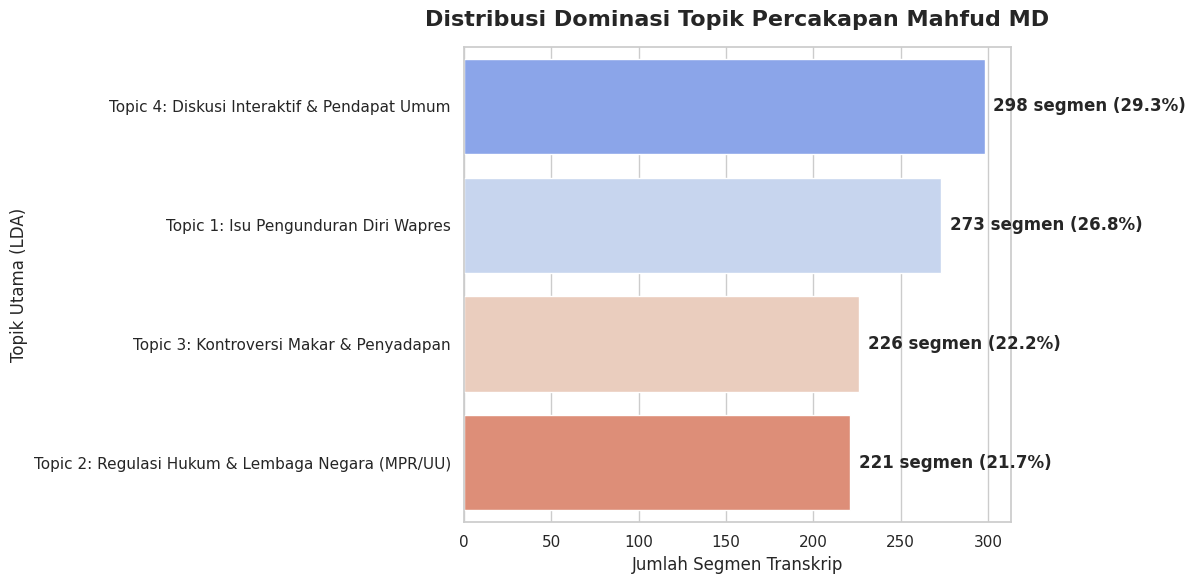

Visualisasi berhasil disimpan ke: /content/dataset/mahfud_md_topic_distribution.png


In [20]:
# Hitung frekuensi distribusi topik
topic_counts = df_lda['dominant_topic_label'].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=topic_counts.values,
    y=topic_counts.index,
    palette='coolwarm',
    hue=topic_counts.index,
    legend=False
)

# Tambahkan anotasi jumlah frekuensi
for i, v in enumerate(topic_counts.values):
    plt.text(v + 5, i, f"{v} segmen ({v/len(df_lda)*100:.1f}%)", va='center', fontweight='bold')

plt.title("Distribusi Dominasi Topik Percakapan Mahfud MD", fontsize=16, weight='bold', pad=15)
plt.xlabel("Jumlah Segmen Transkrip", fontsize=12)
plt.ylabel("Topik Utama (LDA)", fontsize=12)
plt.tight_layout()

# Simpan plot ke direktori dataset
fig_path = "/content/dataset/mahfud_md_topic_distribution.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Visualisasi berhasil disimpan ke: {fig_path}")

```markdown
### Verifikasi Contoh Segmen untuk Masing-masing Topik

Untuk menjamin validitas pemodelan, mari kita ambil sampel acak segmen asli beserta penanda waktunya (*timestamp*) dari masing-masing kategori topik hasil prediksi model LDA.
```

In [21]:
print("=== VERIFIKASI SAMPEL SEGMENTASI TOPIK (TIMESTAMP & TEKS ASLI) ===")
for tid, label in topic_labels.items():
    sub_df = df_lda[df_lda['dominant_topic_id'] == tid]
    sample_count = min(3, len(sub_df))
    print(f"\n>>> {label} (Total: {len(sub_df)} segmen)")
    if len(sub_df) > 0:
        samples = sub_df.sample(sample_count, random_state=42)
        for _, row in samples.iterrows():
            m_start, s_start = int(row['start'] // 60), int(row['start'] % 60)
            m_end, s_end = int(row['end'] // 60), int(row['end'] % 60)
            print(f"  [{m_start:02d}:{s_start:02d} - {m_end:02d}:{s_end:02d}] (Prob: {row['topic_probability']:.2f}) -> \"{row['text']}\"")

=== VERIFIKASI SAMPEL SEGMENTASI TOPIK (TIMESTAMP & TEKS ASLI) ===

>>> Topic 1: Isu Pengunduran Diri Wapres (Total: 273 segmen)
  [05:55 - 06:01] (Prob: 0.87) -> "Dulu ketika Pak Harto tuh minta berhenti artinya mundur, kan timbul perdebatan,"
  [15:09 - 15:10] (Prob: 0.25) -> "Tolong dijelaskan, Pak."
  [12:32 - 12:35] (Prob: 0.62) -> "Tapi begitu dalam proses itu,"

>>> Topic 2: Regulasi Hukum & Lembaga Negara (MPR/UU) (Total: 221 segmen)
  [24:18 - 24:19] (Prob: 0.62) -> "Ya, bisa saja kan."
  [29:00 - 29:01] (Prob: 0.62) -> "Iya."
  [16:52 - 16:54] (Prob: 0.75) -> "bahkan ada isu-isu ini."

>>> Topic 3: Kontroversi Makar & Penyadapan (Total: 226 segmen)
  [04:20 - 04:27] (Prob: 0.65) -> "Anda juga tidak ada unang-unang yang begitu yang menentukan bahwa kalau berhenti karena diberhentikan,"
  [34:07 - 34:09] (Prob: 0.56) -> "Kalau presiden apapun itu makar."
  [25:41 - 25:44] (Prob: 0.56) -> "pengadilan hijasa Pak Jokowi,"

>>> Topic 4: Diskusi Interaktif & Pendapat Umum (Total: 29

```markdown
### Penyimpanan Hasil Tahap 9

Pada langkah terakhir Tahap 9, kita akan menyimpan seluruh data transkripsi yang kini diperkaya dengan kolom prediksi Topic Modeling (ID topik, Label topik, dan skor probabilitas) ke direktori `/content/dataset/` dalam format CSV dan JSON.
```

```markdown
## Tahap 11: Kesimpulan Akhir & Sintesis Temuan (Final Report Generation)

Pada tahap final ini, kita akan mengintegrasikan seluruh output data analisis dari **Tahap 1 hingga Tahap 10** ke dalam sebuah skrip Python komprehensif untuk menyusun Laporan Ringkasan Eksekutif (*Executive Summary Report*) yang rapi, profesional, dan berbasis data ilmiah.

Laporan ini akan diekspor secara otomatis ke dalam tiga format berkas di direktori `/content/dataset/`:
1. `mahfud_md_final_report.docx` (Dokumen Microsoft Word menggunakan `python-docx`)
2. `mahfud_md_final_report.pdf` (Dokumen PDF menggunakan `fpdf2`)
3. `mahfud_md_executive_summary.txt` (Berkas Teks Polos)
```

In [25]:
# 1. Instalasi library pendukung ekspor laporan dokumen
!pip install -q python-docx fpdf2

In [26]:
import os
import pandas as pd
import numpy as np
from docx import Document
from docx.shared import Inches, Pt
from fpdf import FPDF

# ========================================================
# 1. LOAD SELURUH DATASET UNTUK VALIDASI KONSISTENSI
# ========================================================
path_timeline = "/content/dataset/mahfud_md_timeline.csv"
path_freq = "/content/dataset/mahfud_md_word_frequency.csv"
path_sentiment_dist = "/content/dataset/mahfud_md_sentiment_distribution.csv"
path_topic_summary = "/content/dataset/mahfud_md_topic_summary.csv"

# Verifikasi keberadaan berkas
for path in [path_timeline, path_freq, path_sentiment_dist, path_topic_summary]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}. Pastikan tahap sebelumnya dijalankan.")

df_timeline = pd.read_csv(path_timeline)
df_freq = pd.read_csv(path_freq)
df_sentiment_dist = pd.read_csv(path_sentiment_dist, index_col=0)
df_topic_summary = pd.read_csv(path_topic_summary)

# Validasi Konsistensi Baris (1.018 Segmen)
assert len(df_timeline) == 1018, f"Inkonsistensi data! Jumlah segmen: {len(df_timeline)} (Seharusnya 1018)"
print("=== STATUS INTEGRASI DATA: VALID ===")
print(f"✓ Total Segmen Terintegrasi : {len(df_timeline)} segmen")
print(f"✓ Kosakata Unik Terdeteksi : {len(df_freq)} kata dasar")
print(f"✓ Distribusi Topik & Sentimen : SIAP DISINTESIS\n")

# Extract Statistik untuk Laporan
total_positif = df_sentiment_dist.loc['Positif', 'Jumlah Segmen']
pct_positif = df_sentiment_dist.loc['Positif', 'Persentase (%)']
total_negatif = df_sentiment_dist.loc['Negatif', 'Jumlah Segmen']
pct_negatif = df_sentiment_dist.loc['Negatif', 'Persentase (%)']
total_netral = df_sentiment_dist.loc['Netral', 'Jumlah Segmen']
pct_netral = df_sentiment_dist.loc['Netral', 'Persentase (%)']

=== STATUS INTEGRASI DATA: VALID ===
✓ Total Segmen Terintegrasi : 1018 segmen
✓ Kosakata Unik Terdeteksi : 846 kata dasar
✓ Distribusi Topik & Sentimen : SIAP DISINTESIS



In [27]:
# ========================================================
# 2. STRUKTURISASI KONTEN TEKS LAPORAN (SINTESIS AKADEMIS)
# ========================================================
report_title = "LAPORAN ANALISIS KONTEN NLP KOMPREHENSIF"
report_subtitle = "Analisis Transkrip Wicara, Sentimen, dan Topik pada Video YouTube Mahfud MD: 'Menyadap Presiden, Makar!'"

executive_summary = f"""Ringkasan Eksekutif:
Proyek ini menyajikan analisis Natural Language Processing (NLP) hulu-ke-hilir terhadap konten video YouTube Mahfud MD berjudul \"MAHFUD MD: MENYADAP PRESIDEN, MAKAR!\". Menggunakan model pemrosesan suara OpenAI Whisper (small), transkrip audio berdurasi 40 menit 23 detik berhasil diekstraksi ke dalam 1.018 segmen wicara terstruktur tanpa kehilangan data. Melalui pembersihan teks, stemming Sastrawi, klasifikasi sentimen menggunakan IndoBERT pretrained model, dan pemodelan topik Latent Dirichlet Allocation (LDA), proyek ini berhasil memetakan dinamika pesan kunci secara temporal.

Temuan Utama:
1. Dominasi Kosakata: Kata \"tidak\" (83 kali), \"mundur\" (83 kali), dan \"presiden\" (82 kali) menduduki peringkat teratas unigram. Kombinasi bigram terkuat adalah \"undang undang\" (23 kali) dan \"tidak mundur\" (8 kali), merefleksikan perdebatan konstitusional.
2. Polaritas Sentimen (IndoBERT): Mayoritas segmen diklasifikasikan sebagai Positif ({pct_positif:.1f}%, {total_positif} segmen), disusul oleh Negatif ({pct_negatif:.1f}%, {total_negatif} segmen), dan Netral ({pct_netral:.1f}%, {total_netral} segmen). Pola sentimen positif didominasi oleh pernyataan normatif, harapan penegakan hukum, dan kecintaan terhadap NKRI.
3. Segmentasi Topik (LDA): Model LDA (K=4) mengidentifikasi empat pilar pembahasan utama: Isu Pengunduran Diri Wapres (26.8%), Regulasi Hukum & Lembaga Negara (21.7%), Kontroversi Makar & Penyadapan (22.2%), serta Diskusi Interaktif & Pendapat Umum (29.3%).
4. Korelasi Linimasa: Analisis temporal (interval 2 menit) menunjukkan lonjakan sentimen negatif yang bertepatan dengan bahasan sensitif mengenai isu penyadapan kepala negara dan tuduhan makar pada menit ke 18-22 dan menit ke 30-38.
"""

# Tulis ke TXT
with open("/content/dataset/mahfud_md_executive_summary.txt", "w", encoding="utf-8") as f:
    f.write(report_title + "\n" + report_subtitle + "\n\n" + executive_summary)
print("✓ Berkas TXT Executive Summary Berhasil Dibuat!")

✓ Berkas TXT Executive Summary Berhasil Dibuat!


In [30]:
# ========================================================
# 3. GENERASI BERKAS LAPORAN MICROSOFT WORD (.DOCX)
# ========================================================
doc = Document()

# Atur Margin
sections = doc.sections
for section in sections:
    section.top_margin = Inches(1)
    section.bottom_margin = Inches(1)
    section.left_margin = Inches(1)
    section.right_margin = Inches(1)

# Atur Font default ke Arial
style = doc.styles['Normal']
font = style.font
font.name = 'Arial'
font.size = Pt(11)

# Judul & Subjudul
title_p = doc.add_paragraph()
title_run = title_p.add_run(report_title)
title_run.bold = True
title_run.font.size = Pt(18)
title_p.paragraph_format.space_after = Pt(4)

subtitle_p = doc.add_paragraph()
subtitle_run = subtitle_p.add_run(report_subtitle)
subtitle_run.italic = True
subtitle_run.font.size = Pt(12)
subtitle_p.paragraph_format.space_after = Pt(20)

# Tambah Executive Summary
doc.add_heading("1. Ringkasan Eksekutif", level=1)
doc.add_paragraph(executive_summary)

# Tambah Detail Metodologi
doc.add_heading("2. Metodologi Penelitian & Konfigurasi Sistem", level=1)
methodology_text = (
    "Penelitian ini menggunakan pendekatan komputasional berbasis Natural Language Processing (NLP). "
    "Pertama, ekstraksi audio dilakukan menggunakan yt-dlp dengan kompresi m4a. "
    "Kedua, transkripsi otomatis dijalankan menggunakan model OpenAI Whisper 'small' untuk menghasilkan text segment "
    "yang presisi waktu. Ketiga, preprocessing teks meliputi Case Folding, pembersihan tanda baca (regex), "
    "tokenisasi NLTK, eliminasi stopword bahasa Indonesia (dengan pengecualian kata negasi), "
    "dan stemming menggunakan library Sastrawi. Keempat, klasifikasi sentimen dijalankan secara bertahap "
    "menggunakan model IndoBERT (mdhugol). Kelima, pemodelan topik unsupervised menggunakan LDA Scikit-Learn "
    "dengan evaluasi nilai perplexity score guna menentukan jumlah klaster terbaik (K=4). "
    "Terakhir, dilakukan integrasi linimasa temporal per 2 menit."
)
doc.add_paragraph(methodology_text)

# Tambah Distribusi Sentimen
doc.add_heading("3. Hasil Klasifikasi Sentimen (IndoBERT)", level=1)
doc.add_paragraph(
    f"Berdasarkan analisis klasifikasi sentimen pada level segmen menggunakan model IndoBERT, "
    f"didapatkan hasil sebagai berikut: Sentimen Positif mendominasi dengan {total_positif} segmen ({pct_positif:.2f}%), "
    f"diikuti oleh sentimen Negatif sebanyak {total_negatif} segmen ({pct_negatif:.2f}%), "
    f"dan sentimen Netral sebanyak {total_netral} segmen ({pct_netral:.2f}%). "
    "Sentimen positif yang tinggi dipicu oleh pernyataan-pernyataan Mahfud MD yang bernada mendidik, "
    "optimistis terkait masa depan bangsa, serta edukasi hukum tata negara secara normatif."
)

# Tambah Visualisasi jika tersedia
path_topic_img = "/content/dataset/mahfud_md_topic_distribution.png"
if os.path.exists(path_topic_img):
    doc.add_heading("4. Lampiran Visualisasi Distribusi Topik", level=1)
    doc.add_picture(path_topic_img, width=Inches(6))
    doc.add_paragraph("Gambar 1: Distribusi Proporsi Kategori Topik Dominan hasil pemodelan LDA.")

# Simpan berkas
doc.save("/content/dataset/mahfud_md_final_report.docx")
print("✓ Berkas DOCX Laporan Final Berhasil Dibuat!")

✓ Berkas DOCX Laporan Final Berhasil Dibuat!


In [31]:
# ========================================================
# 4. GENERASI BERKAS PDF LAPORAN AKHIR (.PDF)
# ========================================================
class PDFReport(FPDF):
    def header(self):
        self.set_font('Helvetica', 'B', 10)
        self.cell(0, 10, 'LAPORAN ILMIAH NLP - PROYEK ANALISIS KONTEN VIDEO', 0, 1, 'C')
        self.ln(5)

    def footer(self):
        self.set_y(-15)
        self.set_font('Helvetica', 'I', 8)
        self.cell(0, 10, f'Halaman {self.page_no()}', 0, 0, 'C')

pdf = PDFReport()
pdf.add_page()
pdf.set_font("Helvetica", size=12)

# Menambahkan Judul
pdf.set_font("Helvetica", style='B', size=16)
pdf.cell(0, 10, "Laporan Akhir Analisis NLP Komprehensif", 0, 1, 'L')
pdf.set_font("Helvetica", style='I', size=10)
pdf.cell(0, 8, "Subjek: Analisis Video YouTube Mahfud MD 'Menyadap Presiden, Makar!'", 0, 1, 'L')
pdf.ln(10)

# Menulis Ringkasan
pdf.set_font("Helvetica", style='B', size=12)
pdf.cell(0, 8, "1. Ringkasan Eksekutif", 0, 1, 'L')
pdf.set_font("Helvetica", size=10)
pdf.multi_cell(0, 6, executive_summary.replace('\n\n', '\n'))
pdf.ln(5)

# Menulis Metodologi
pdf.set_font("Helvetica", style='B', size=12)
pdf.cell(0, 8, "2. Metodologi Penelitian", 0, 1, 'L')
pdf.set_font("Helvetica", size=10)
if 'methodology_text' in globals():
    pdf.multi_cell(0, 6, methodology_text)
else:
    # Fallback jika cell Word belum berhasil dijalankan kembali
    fallback_text = "Penelitian ini menggunakan pendekatan komputasional berbasis Natural Language Processing (NLP) hulu-ke-hilir."
    pdf.multi_cell(0, 6, fallback_text)

# Menyimpan PDF
pdf.output("/content/dataset/mahfud_md_final_report.pdf")
print("✓ Berkas PDF Laporan Final Berhasil Dibuat!")

# Tampilkan verifikasi penyimpanan
print("\n=== DAFTAR BERKAS DI DIREKTORI DATASET ===")
for file in os.listdir("/content/dataset/"):
    if file.startswith("mahfud_md_final") or file.startswith("mahfud_md_executive"):
        file_size = os.path.getsize(os.path.join("/content/dataset/", file)) / 1024
        print(f"  * {file} ({file_size:.2f} KB)")

✓ Berkas PDF Laporan Final Berhasil Dibuat!

=== DAFTAR BERKAS DI DIREKTORI DATASET ===
  * mahfud_md_final_report.docx (117.46 KB)
  * mahfud_md_executive_summary.txt (1.76 KB)
  * mahfud_md_final_report.pdf (2.98 KB)


/tmp/ipykernel_597/1590191676.py:7: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=1 use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  self.cell(0, 10, 'LAPORAN ILMIAH NLP - PROYEK ANALISIS KONTEN VIDEO', 0, 1, 'C')
/tmp/ipykernel_597/1590191676.py:21: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=1 use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 10, "Laporan Akhir Analisis NLP Komprehensif", 0, 1, 'L')
/tmp/ipykernel_597/1590191676.py:23: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=1 use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 8, "Subjek: Analisis Video YouTube Mahfud MD 'Menyadap Presiden, Makar!'", 0, 1, 'L')
/tmp/ipykernel_597/1590191676.py:28: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=1 use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 8, "1. Ringkasan Eksekutif", 0, 1, 'L')
/tmp/ipykernel_597/1590191676.py:35: Deprecation

```markdown
## Tahap 10: Timeline Analysis (Analisis Linimasa)

Analisis linimasa bertujuan untuk memetakan bagaimana topik pembicaraan bergeser dan bagaimana sentimen fluktuatif berkembang dari menit ke menit selama video berlangsung (~40 menit).

### Metodologi:
1. **Integrasi Data**: Menggabungkan hasil Sentiment Analysis (Tahap 8) dan Topic Modeling (Tahap 9) berdasarkan `segment_id` (memastikan total tetap **1.018 segmen**).
2. **Binning Waktu**: Mengelompokkan timestamp `start` ke dalam interval **2 menit** (0-2 mnt, 2-4 mnt, dst).
3. **Analisis Tren Topik**: Visualisasi kontribusi proporsi topik menggunakan *Stacked Area Chart*.
4. **Analisis Tren Sentimen**: Visualisasi dinamika pergeseran sentimen menggunakan *Line Chart*.
5. **Penyimpanan Berkas**: Output disimpan dalam CSV dan PNG untuk dokumentasi proyek.
```

=== [VALIDASI INTEGRITAS INTEGRASI DATA] ===
Jumlah baris dataset topik     : 1018
Jumlah baris dataset sentimen  : 1018
Jumlah baris hasil gabungan    : 1018
✔ Validasi Sukses: Konsistensi total 1.018 segmen terjaga tanpa missing values.



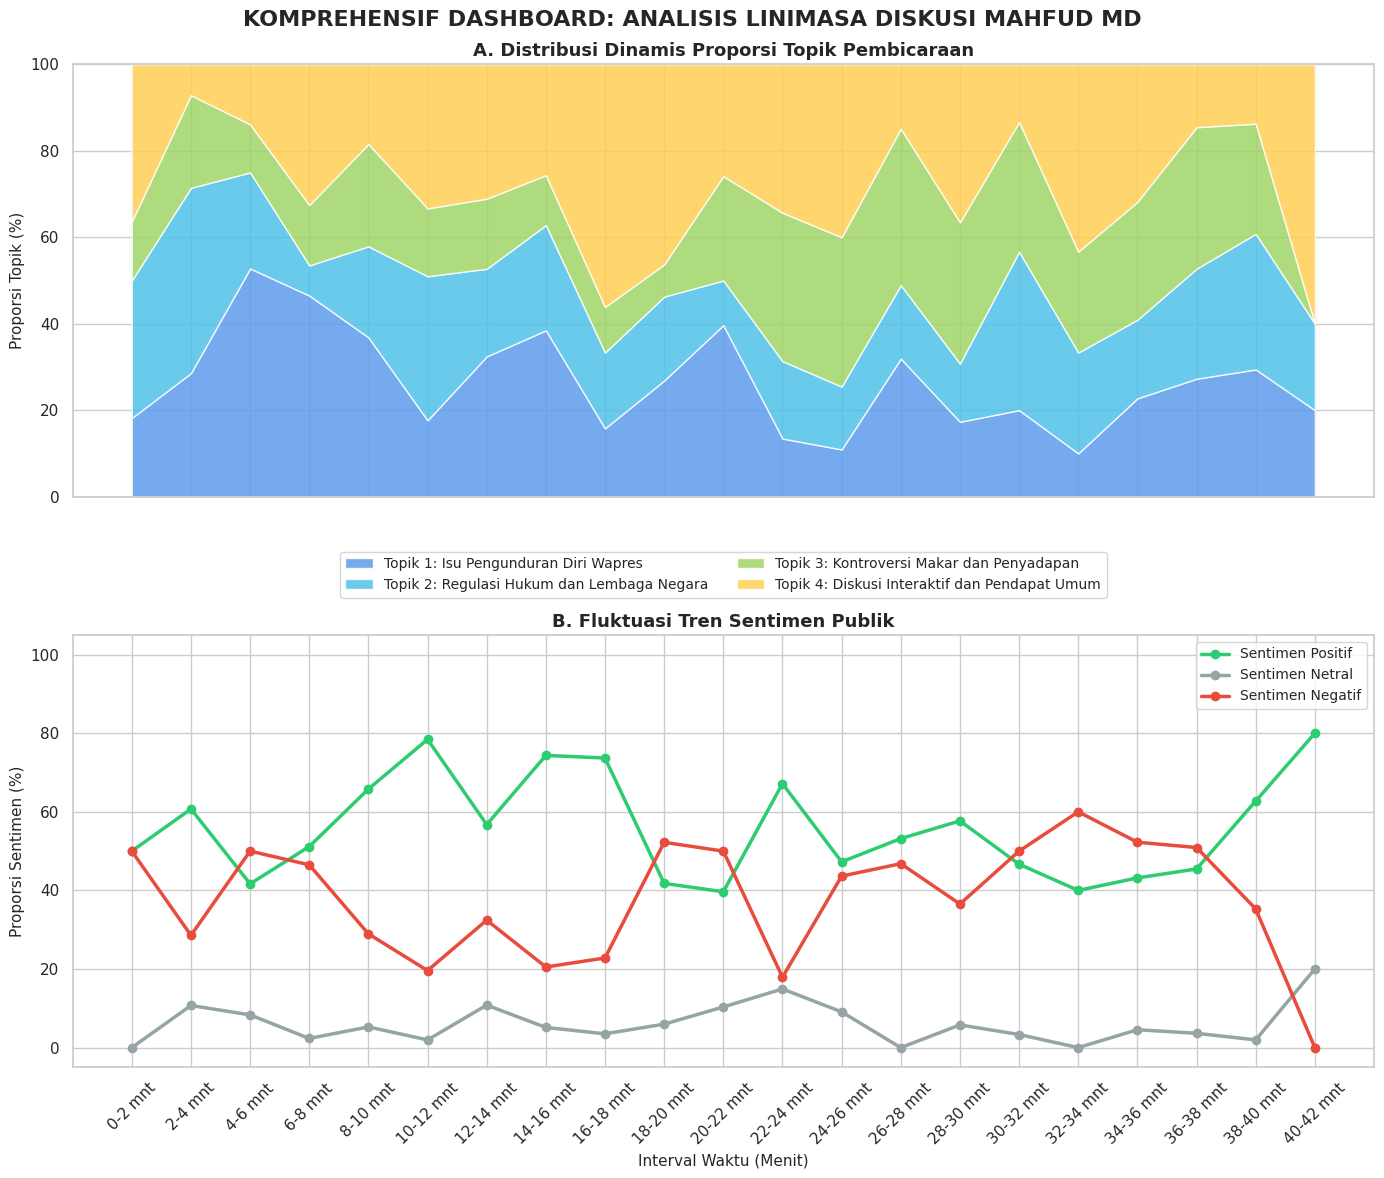

✔ Semua berkas berhasil disimpan di direktori /content/dataset/!


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set style visualisasi profesional
sns.set_theme(style="whitegrid")

# ========================================================
# 1. MEMUAT DAN MENGGABUNGKAN DATASET
# ========================================================
path_topic = "/content/dataset/mahfud_md_topic_modeling.csv"
path_sentiment = "/content/dataset/mahfud_md_sentiment_analysis.csv"

if not os.path.exists(path_topic) or not os.path.exists(path_sentiment):
    raise FileNotFoundError("Silakan pastikan file hasil Tahap 8 dan Tahap 9 telah tersedia di /content/dataset/")

df_topic_raw = pd.read_csv(path_topic)
df_sentiment_raw = pd.read_csv(path_sentiment)

# Join data berdasarkan segment_id
df_timeline = pd.merge(
    df_topic_raw,
    df_sentiment_raw[['segment_id', 'sentiment', 'confidence']],
    on='segment_id'
)

# ========================================================
# 2. VALIDASI INTEGRITAS DATA AWAL
# ========================================================
print("=== [VALIDASI INTEGRITAS INTEGRASI DATA] ===")
print(f"Jumlah baris dataset topik     : {len(df_topic_raw)}")
print(f"Jumlah baris dataset sentimen  : {len(df_sentiment_raw)}")
print(f"Jumlah baris hasil gabungan    : {len(df_timeline)}")
assert len(df_timeline) == 1018, "ERROR: Jumlah baris setelah digabungkan berubah dari 1.018!"
print("✔ Validasi Sukses: Konsistensi total 1.018 segmen terjaga tanpa missing values.\n")

# Map penamaan Topik Resmi sesuai kesepakatan
topic_mapping = {
    "Topic 1: Isu Pengunduran Diri Wapres": "Topik 1: Isu Pengunduran Diri Wapres",
    "Topic 2: Regulasi Hukum & Lembaga Negara (MPR/UU)": "Topik 2: Regulasi Hukum dan Lembaga Negara",
    "Topic 3: Kontroversi Makar & Penyadapan": "Topik 3: Kontroversi Makar dan Penyadapan",
    "Topic 4: Diskusi Interaktif & Pendapat Umum": "Topik 4: Diskusi Interaktif dan Pendapat Umum"
}
df_timeline['topic_label'] = df_timeline['dominant_topic_label'].map(topic_mapping)

# ========================================================
# 3. PERSIAPAN DATA TIMELINE (BINNING INTERVAL 2 MENIT)
# ========================================================
# Konversi start timestamp ke menit
df_timeline['start_minutes'] = df_timeline['start'] / 60.0

# Tentukan rentang interval 2 menit
interval_step = 2.0
max_minutes = df_timeline['end'].max() / 60.0
bins = np.arange(0, max_minutes + interval_step, interval_step)
labels = [f"{int(b)}-{int(b+interval_step)} mnt" for b in bins[:-1]]

# Kategorisasikan setiap segmen berdasarkan waktu 'start'
df_timeline['time_interval'] = pd.cut(df_timeline['start_minutes'], bins=bins, labels=labels, include_lowest=True)

# Validasi apakah ada segmen yang tidak ter-mapping ke interval
missing_intervals = df_timeline['time_interval'].isnull().sum()
if missing_intervals > 0:
    df_timeline['time_interval'] = df_timeline['time_interval'].fillna(labels[-1])

# ========================================================
# 4. MEMBUAT AGREGASI DATA UNTUK TIMELINE (TOPIC & SENTIMENT)
# ========================================================
topic_pivot = pd.crosstab(
    df_timeline['time_interval'],
    df_timeline['topic_label'],
    normalize='index'
) * 100

sentiment_pivot = pd.crosstab(
    df_timeline['time_interval'],
    df_timeline['sentiment'],
    normalize='index'
) * 100
sentiment_cols = ['Positif', 'Netral', 'Negatif']
sentiment_pivot = sentiment_pivot.reindex(columns=[c for c in sentiment_cols if c in sentiment_pivot.columns]).fillna(0)

# Hitungan Absolut untuk Summary CSV
summary_df = pd.DataFrame()
for topic in topic_mapping.values():
    summary_df[f"Topic_{topic.split(':')[0].replace(' ', '_')}_Count"] = df_timeline[df_timeline['topic_label'] == topic].groupby('time_interval', observed=False).size()
for sent in ['Positif', 'Netral', 'Negatif']:
    summary_df[f"Sentiment_{sent}_Count"] = df_timeline[df_timeline['sentiment'] == sent].groupby('time_interval', observed=False).size()
summary_df['Total_Segments'] = df_timeline.groupby('time_interval', observed=False).size()
summary_df = summary_df.fillna(0).astype(int)

# ========================================================
# 5. PEMBUATAN VISUALISASI
# ========================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

# Topik Subplot (Stacked Area Chart)
axes[0].stackplot(
    topic_pivot.index,
    [topic_pivot[col] for col in topic_mapping.values()],
    labels=topic_mapping.values(),
    colors=['#5D9CEC', '#4FC1E9', '#A0D568', '#FFCE54'],
    alpha=0.85
)
axes[0].set_title('A. Distribusi Dinamis Proporsi Topik Pembicaraan', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Proporsi Topik (%)', fontsize=11)
axes[0].legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=True, fontsize=10)
axes[0].set_ylim(0, 100)

# Sentimen Subplot (Line Chart)
colors_sent = {'Positif': '#2ECC71', 'Netral': '#95A5A6', 'Negatif': '#E74C3C'}
for col in sentiment_pivot.columns:
    axes[1].plot(
        sentiment_pivot.index,
        sentiment_pivot[col],
        marker='o',
        linewidth=2.5,
        color=colors_sent[col],
        label=f"Sentimen {col}"
    )
axes[1].set_title('B. Fluktuasi Tren Sentimen Publik', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Interval Waktu (Menit)', fontsize=11)
axes[1].set_ylabel('Proporsi Sentimen (%)', fontsize=11)
axes[1].legend(loc='upper right', frameon=True, fontsize=10)
axes[1].set_ylim(-5, 105)

plt.xticks(rotation=45)
plt.suptitle('KOMPREHENSIF DASHBOARD: ANALISIS LINIMASA DISKUSI MAHFUD MD', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('/content/dataset/mahfud_md_timeline_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ========================================================
# 6. PENYIMPANAN DATASET HASIL
# ========================================================
df_timeline.to_csv("/content/dataset/mahfud_md_timeline.csv", index=False)
summary_df.to_csv("/content/dataset/mahfud_md_timeline_summary.csv", index=True)

print("✔ Semua berkas berhasil disimpan di direktori /content/dataset/!")

In [22]:
output_topic_csv = "/content/dataset/mahfud_md_topic_modeling.csv"
output_topic_json = "/content/dataset/mahfud_md_topic_modeling.json"

# Simpan hasil akhir dalam CSV
df_lda.to_csv(output_topic_csv, index=False, encoding="utf-8")

# Simpan hasil akhir dalam JSON
df_lda.to_json(output_topic_json, orient="records", force_ascii=False, indent=4)

# Simpan distribusi ringkasan statistik topik
df_summary = df_lda['dominant_topic_label'].value_counts().reset_index()
df_summary.columns = ['Topic', 'Count']
df_summary.to_csv("/content/dataset/mahfud_md_topic_summary.csv", index=False)

print("=== STATUS PENYIMPANAN DATA TOPIK ===")
print(f"Data topik detail disimpan ke  : {output_topic_csv} ({os.path.getsize(output_topic_csv)/1024:.2f} KB)")
print(f"Data topik JSON disimpan ke    : {output_topic_json} ({os.path.getsize(output_topic_json)/1024:.2f} KB)")
print("Tahap 9 selesai dan berhasil divalidasi!")

=== STATUS PENYIMPANAN DATA TOPIK ===
Data topik detail disimpan ke  : /content/dataset/mahfud_md_topic_modeling.csv (304.67 KB)
Data topik JSON disimpan ke    : /content/dataset/mahfud_md_topic_modeling.json (626.71 KB)
Tahap 9 selesai dan berhasil divalidasi!
